# Safety-Aware Segmentation on IDD-AW — Interim Analysis Notebook
**Project:** Safety-aware segmentation of Indian unstructured roads in adverse weather (RGB–NIR fusion and a hierarchy-based loss).
**Author:** Karan Raj Modgil · QM640 Data Analytics Capstone

One notebook, top to bottom:
1. Setup · 2. Data loading · 3. Data cleaning · 4. Sequence-level split · 5. Exploratory data analysis (EDA)
6. Naive baselines · 7. SegFormer training (RGB, RGB+NIR, hierarchy-aware loss) · 8. Evaluation
9. Statistical tests by research question · 10. Sample-size recheck · 11. Feature importance (exploratory) · 12. Export

**How to run:** Runtime → Change runtime type → **T4 GPU**. Put `IDDAW_compact.zip` in *My Drive*. Then Runtime → Run all.
Every heavy step saves its result to Google Drive (`iddaw_outputs/`), so if Colab disconnects, just **Run all** again and it continues where it stopped.

The notebook is set to the **full run** (`QUICK_TEST = False`): all three models are trained in full and evaluated on all test images (about 5–6 hours on a T4).

In [1]:
# ============================== 0. CONFIGURATION ==============================
QUICK_TEST = False         # False = full run (all 3 models, 8,000 steps each, all test images). True = 10-min trial only.

ZIP_PATH = "/content/drive/MyDrive/IDDAW_compact.zip"   # where you uploaded the zip
DATA_DIR = "/content/IDDAW_compact"                      # unzipped here (fast local disk)
OUT_DIR  = "/content/drive/MyDrive/iddaw_outputs"         # all results are saved here

SEED = 42
IMG_W, IMG_H = 1024, 768       # compact image size
CROP = 512                     # random training crop
BATCH = 8                      # lower to 4 if you get "CUDA out of memory"
STEPS = 8000                   # training steps per model
LR = 6e-5                      # encoder learning rate (decoder head uses 10x)
WARMUP = 500
EVAL_EVERY = 1000              # quick validation check during training
CKPT_EVERY = 500               # checkpoint to Drive
VAL_MONITOR = 120              # validation images used for the quick check
TD_LAMBDA = 1.0                # strength of the hierarchy (tree-distance) penalty
MODELS = ["rgb_ce", "rgbn_ce", "rgb_td"]   # Model 1, Model 2, Model 3 (remove one to skip it)

TEST_FRAC, VAL_FRAC = 0.25, 0.15   # target share of images per weather condition in test / val (rest = train)
TEST_MIN_PER_COND = 217            # minimum test images per condition (from the sample-size plan)
MIN_MISS_AREA = 64                 # pixels (at 1024x768) for a region to count as a dangerous miss
N_BOOT = 2000                      # bootstrap resamples

EVAL_LIMIT = None                  # None = all test images
if QUICK_TEST:
    STEPS, EVAL_EVERY, CKPT_EVERY, WARMUP, VAL_MONITOR = 40, 20, 20, 10, 16
    EVAL_LIMIT, N_BOOT = 48, 200
    OUT_DIR = OUT_DIR + "_quicktest"
print("QUICK_TEST =", QUICK_TEST, "| outputs ->", OUT_DIR)

QUICK_TEST = False | outputs -> /content/drive/MyDrive/iddaw_outputs


## 1. Setup

In [2]:
import os, sys, json, time, math, random, glob, shutil, zipfile, subprocess, platform, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "lightgbm"], check=False)

import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import cv2
from scipy import stats
cv2.setNumThreads(0)
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.precision", 3)

os.makedirs(OUT_DIR, exist_ok=True)
FIG_DIR = os.path.join(OUT_DIR, "figures"); TAB_DIR = os.path.join(OUT_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)

gpu = subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout if shutil.which("nvidia-smi") else "no GPU found"
print(gpu)

env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "opencv": cv2.__version__}
try:
    import torch, transformers
    env.update(torch=torch.__version__, transformers=transformers.__version__,
               cuda=torch.cuda.is_available(), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
except ImportError:
    torch = None
json.dump(env, open(os.path.join(OUT_DIR, "environment.json"), "w"), indent=2)
print(env)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
COND_ORDER = ["RAIN", "FOG", "LOWLIGHT", "SNOW"]
COND_NAME = {"RAIN": "Rain", "FOG": "Fog", "LOWLIGHT": "Low light", "SNOW": "Snow"}
COND_COLOR = {"RAIN": "#3B6FB6", "FOG": "#8C8C8C", "LOWLIGHT": "#5B3A8C", "SNOW": "#4FA3A5"}

def savefig(fig, name):
    path = os.path.join(FIG_DIR, name + ".png")
    fig.savefig(path, bbox_inches="tight", facecolor="white"); plt.show(); print("saved", path)

def savetab(df, name, index=False):
    df.to_csv(os.path.join(TAB_DIR, name + ".csv"), index=index); display(df)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    if torch is not None:
        torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Mounted at /content/drive
Tue Oct 27 10:09:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

**Observations**

- Ran on a **Tesla T4 GPU (15 GB)** with PyTorch 2.11 and transformers 5.20, in full-run mode (`QUICK_TEST = False`).
- All software versions are saved to `environment.json`, so the run can be reproduced.

## 2. Data loading
The zip holds the compact copy made by `step0_make_compact.py` (in the GitHub repo): RGB and NIR at 1024×768 (JPEG, quality 95),
and 26-class level-3 label masks drawn from the original polygon files with the official IDD mapping (255 = ignore).

In [3]:
if not os.path.exists(os.path.join(DATA_DIR, "pairs.csv")):
    local_zip = "/content/IDDAW_compact.zip" if IN_COLAB else ZIP_PATH
    if IN_COLAB and not os.path.exists(local_zip):
        print("copying zip from Drive ..."); shutil.copy(ZIP_PATH, local_zip)
    print("unzipping ..."); t = time.time()
    with zipfile.ZipFile(local_zip) as z:
        z.extractall(os.path.dirname(DATA_DIR))
    print(f"done in {time.time()-t:.0f}s")

pairs = pd.read_csv(os.path.join(DATA_DIR, "pairs.csv"), dtype={"sequence": str, "frame": str})
pairs["frame"] = pairs["frame"].str.zfill(8)
log0 = pd.read_csv(os.path.join(DATA_DIR, "cleaning_log.csv"))
def paths(r):
    b = os.path.join(DATA_DIR, r.split, r.condition)
    return (os.path.join(b, "rgb", r.sequence, r.frame + "_rgb.jpg"),
            os.path.join(b, "nir", r.sequence, r.frame + "_nir.jpg"),
            os.path.join(b, "mask", r.sequence, r.frame + "_mask.png"))
pairs[["rgb_path", "nir_path", "mask_path"]] = pd.DataFrame([paths(r) for r in pairs.itertuples()], index=pairs.index)
pairs["image_id"] = pairs.split + "/" + pairs.condition + "/" + pairs.sequence + "/" + pairs.frame
pairs["group"] = pairs.condition + "_" + pairs.sequence          # drive sequence = unit of the split
print(len(pairs), "pairs;", pairs.group.nunique(), "drive sequences")
display(pd.crosstab(pairs.split, pairs.condition, margins=True))

copying zip from Drive ...
unzipping ...
done in 8s
3905 pairs; 161 drive sequences


condition,FOG,LOWLIGHT,RAIN,SNOW,All
split,,,,,
train,1033,684,1062,651,3430
val,154,100,120,101,475
All,1187,784,1182,752,3905


**Observations**

- **3,905 RGB–NIR pairs** from **161 drive sequences** were loaded from the compact copy (unzipped in 6–8 s).
- Rain (1,182) and fog (1,187) have the most images; low light (784) and snow (752) have about a third fewer.
- Low light and snow therefore have the least training data, so weaker results are expected there.

### Labels used (26 level-3 classes, official IDD-AW benchmark)
Vulnerable road users (VRU) = person (animals are merged into *person* at level 3) and rider.
Drivable surface = road and drivable fallback (which includes parking).

In [4]:
CLASSES = ["road", "drivable fallback", "sidewalk", "non drivable fallback", "person", "rider", "motorcycle", "bicycle",
           "autorickshaw", "car", "truck", "bus", "vehicle fallback", "curb", "wall", "fence", "guard rail", "billboard",
           "traffic sign", "traffic light", "pole", "obs-str-bar-fallback", "building", "bridge", "vegetation", "sky"]
NC, IGNORE = len(CLASSES), 255
VRU, DRIVABLE = [4, 5], [0, 1]
IMP = ["person", "rider", "motorcycle", "bicycle", "autorickshaw", "car", "truck", "bus"]   # official "important" classes
VEHICLE_IDS = [6, 7, 8, 9, 10, 11, 12]

# Official IDD-AW semantic hierarchy (from safe_iou.py in the authors' toolkit): N1 = near, N2 = medium, rest = far.
H = {"road": ([], ["drivable fallback"]), "drivable fallback": ([], ["road"]),
     "sidewalk": ([], ["non drivable fallback"]), "non drivable fallback": ([], ["sidewalk"]),
     "person": ([], ["rider"]), "rider": ([], ["person"]),
     "motorcycle": (["bicycle"], ["autorickshaw", "car", "truck", "bus", "vehicle fallback"]),
     "bicycle": (["motorcycle"], ["autorickshaw", "car", "truck", "bus", "vehicle fallback"]),
     "autorickshaw": (["car"], ["bicycle", "motorcycle", "truck", "bus", "vehicle fallback"]),
     "car": (["autorickshaw"], ["bicycle", "motorcycle", "truck", "bus", "vehicle fallback"]),
     "truck": (["bus", "vehicle fallback"], ["motorcycle", "bicycle", "autorickshaw", "car"]),
     "bus": (["truck", "vehicle fallback"], ["motorcycle", "bicycle", "autorickshaw", "car"]),
     "vehicle fallback": (["truck", "bus"], ["motorcycle", "bicycle", "autorickshaw", "car"]),
     "curb": (["wall"], ["fence", "guard rail", "billboard", "traffic sign", "traffic light"]),
     "wall": (["curb"], ["fence", "guard rail", "billboard", "traffic sign", "traffic light"]),
     "fence": (["guard rail"], ["curb", "wall", "billboard", "traffic sign", "traffic light"]),
     "guard rail": (["fence"], ["curb", "wall", "billboard", "traffic sign", "traffic light"]),
     "billboard": (["traffic sign", "traffic light"], ["curb", "wall", "fence", "guard rail"]),
     "traffic sign": (["billboard", "traffic light"], ["curb", "wall", "fence", "guard rail"]),
     "traffic light": (["billboard", "traffic sign"], ["curb", "wall", "fence", "guard rail"]),
     "pole": (["obs-str-bar-fallback"], ["curb", "wall", "fence", "guard rail", "billboard", "traffic light", "traffic sign"]),
     "obs-str-bar-fallback": (["pole"], ["curb", "wall", "fence", "guard rail", "billboard", "traffic light", "traffic sign"]),
     "building": (["bridge"], ["vegetation"]), "bridge": (["building"], ["vegetation"]),
     "vegetation": ([], ["bridge", "building"]), "sky": ([], [])}
CID = {c: i for i, c in enumerate(CLASSES)}
W = np.ones((NC, NC))                      # penalty weight of predicting column j when the truth is row i
for c, (n1, n2) in H.items():
    i = CID[c]; W[i, i] = 0
    for x in n1: W[i, CID[x]] = 1 / 3
    for x in n2: W[i, CID[x]] = 2 / 3
IMP_MASK = np.array([c in IMP for c in CLASSES])

def iou_and_safe_iou(hist):
    """Per-class IoU and Safe IoU exactly as in the official safe_iou.py (rows = truth, columns = prediction)."""
    hist = hist.astype(np.float64)
    den = hist.sum(1) + hist.sum(0) - np.diag(hist)
    pen = np.where(IMP_MASK[:, None], hist * W, hist * W * IMP_MASK[None, :]).sum(1)
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(den > 0, np.diag(hist) / den, np.nan)
        siou = np.where(den > 0, (np.diag(hist) - pen) / den, np.nan)
    return iou, siou

PALETTE = np.zeros((256, 3), np.uint8)
PALETTE[:NC] = [[128, 64, 128], [81, 0, 81], [244, 35, 232], [152, 251, 152], [220, 20, 60], [255, 0, 0], [0, 0, 230],
                [119, 11, 32], [255, 204, 54], [0, 0, 142], [0, 0, 70], [0, 60, 100], [136, 143, 153], [220, 190, 40],
                [102, 102, 156], [190, 153, 153], [180, 165, 180], [174, 64, 67], [220, 220, 0], [250, 170, 30],
                [153, 153, 153], [169, 187, 214], [70, 70, 70], [150, 100, 100], [107, 142, 35], [70, 130, 180]]

def read_rgb(p): return cv2.cvtColor(cv2.imread(p, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
def read_gray(p): return cv2.imread(p, cv2.IMREAD_GRAYSCALE)
def read_mask(p): return cv2.imread(p, cv2.IMREAD_UNCHANGED)

## 3. Data cleaning
### 3.1 Per-image statistics (used for cleaning and EDA)
For every pair: brightness and contrast of RGB and NIR, the RGB–NIR correlation, class pixel counts, the number and size of
vulnerable-road-user regions, and a 64-bit difference hash (dHash) for near-duplicate detection.

In [5]:
def dhash(gray):
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return "%016x" % int("".join("1" if b else "0" for b in bits), 2)

def image_stats(args):
    rgb_p, nir_p, mask_p = args
    out = {}
    rgb = read_rgb(rgb_p); nir = read_gray(nir_p); m = read_mask(mask_p)
    if rgb is None or nir is None or m is None:
        return {"read_error": 1}
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gs = cv2.resize(g, (256, 192), interpolation=cv2.INTER_AREA).astype(np.float32)
    ns = cv2.resize(nir, (256, 192), interpolation=cv2.INTER_AREA).astype(np.float32)
    out.update(read_error=0, rgb_mean=gs.mean(), rgb_std=gs.std(), nir_mean=ns.mean(), nir_std=ns.std(),
               rgb_nir_corr=float(np.corrcoef(gs.ravel(), ns.ravel())[0, 1]) if gs.std() > 0 and ns.std() > 0 else np.nan,
               dhash=dhash(g), h=m.shape[0], w=m.shape[1])
    cnt = np.bincount(m.ravel(), minlength=256)
    for c in range(NC): out[f"px_{c}"] = int(cnt[c])
    out["px_ignore"] = int(cnt[IGNORE])
    vru = np.isin(m, VRU).astype(np.uint8)
    n, _, st, _ = cv2.connectedComponentsWithStats(vru, connectivity=8)
    areas = st[1:, cv2.CC_STAT_AREA] if n > 1 else np.array([], int)
    out.update(n_vru_regions=int((areas >= MIN_MISS_AREA).sum()), vru_areas=";".join(map(str, areas.tolist())))
    return out

STATS_CSV = os.path.join(OUT_DIR, "image_stats.csv")
if os.path.exists(STATS_CSV):
    st = pd.read_csv(STATS_CSV, dtype={"sequence": str, "frame": str, "vru_areas": str, "dhash": str})
    st["frame"] = st["frame"].str.zfill(8)
else:
    from multiprocessing import Pool
    t = time.time()
    with Pool(os.cpu_count()) as pool:
        res = pool.map(image_stats, list(zip(pairs.rgb_path, pairs.nir_path, pairs.mask_path)), chunksize=16)
    st = pd.concat([pairs[["image_id", "split", "condition", "sequence", "frame"]].reset_index(drop=True),
                    pd.DataFrame(res)], axis=1)
    st.to_csv(STATS_CSV, index=False)
    print(f"computed stats for {len(st)} images in {time.time()-t:.0f}s")
df = pairs.merge(st.drop(columns=["split", "condition", "sequence", "frame"]), on="image_id")
PX = [f"px_{c}" for c in range(NC)]
df["labelled_px"] = df[PX].sum(1)
df["vru_share"] = df[[f"px_{c}" for c in VRU]].sum(1) / df.labelled_px
df["drivable_share"] = df[[f"px_{c}" for c in DRIVABLE]].sum(1) / df.labelled_px
df["has_vru"] = (df.n_vru_regions > 0).astype(int)
print(df.shape)

(3905, 62)


**Observations**

- Per-image statistics (brightness, contrast, RGB–NIR correlation, class pixels, people regions) were computed for all 3,905 images.
- These statistics are reused for cleaning, EDA and the failure analysis, so nothing is computed twice.

### 3.2 Missing values, duplicates, and outliers

In [6]:
issues = []
n0 = len(df)
# (a) missing partner files found by step 0 (excluded before this notebook)
for _, r in log0.iterrows():
    issues.append(["Missing partner file", "rgb/nir/label file", "File matching in step 0", 1, "Excluded", r["issue"] + ": " + r["file"]])
# (b) missing files in the compact copy and unreadable files
missing_files = (~df.rgb_path.map(os.path.exists) | ~df.nir_path.map(os.path.exists) | ~df.mask_path.map(os.path.exists)).sum()
read_err = int(df.read_error.sum())
issues.append(["Missing or unreadable files", "rgb, nir, mask", "File check and decode", int(missing_files + read_err), "Excluded if any", "Every pair must have all three files"])
# (c) missing values in the table
na_cells = int(df[["rgb_mean", "nir_mean", "rgb_nir_corr"] + PX].isna().sum().sum())
issues.append(["Missing values (table)", "per-image statistics", "isna() count", na_cells, "None needed" if na_cells == 0 else "Rows dropped", "Statistics are computed for every image"])
# (d) unlabelled pixels (missing labels inside an image)
ign = df.px_ignore / (IMG_W * IMG_H)
issues.append(["Unlabelled pixels", "mask", "Share of pixels = 255", f"mean {ign.mean()*100:.3f}%, max {ign.max()*100:.2f}%",
               "Kept; ignored in loss and metrics", "Standard practice; too few to bias results"])
# (e) exact duplicates (identical RGB file bytes)
df = df.sort_values(["condition", "split", "sequence", "frame"]).reset_index(drop=True)
dup = df.duplicated("rgb_md5", keep="first")
grp = df[df.rgb_md5.isin(df.loc[dup, "rgb_md5"])].groupby("rgb_md5")
cross_cond = sum(g.condition.nunique() > 1 for _, g in grp)
cross_split = sum(g.split.nunique() > 1 for _, g in grp)
issues.append(["Exact duplicates", "rgb image", "MD5 hash of the original file", f"{int(dup.sum())} ({dup.mean()*100:.1f}%) in {grp.ngroups} groups",
               "Removed (first copy kept)", f"Repeated frames inflate counts; {cross_split} groups cross train/val, {cross_cond} groups cross weather folders"])
dup_list = df.loc[df.rgb_md5.isin(df.loc[dup, "rgb_md5"]), ["image_id", "rgb_md5"]]
dup_list.to_csv(os.path.join(TAB_DIR, "duplicate_groups.csv"), index=False)
df = df[~dup].reset_index(drop=True)

# (f) near-duplicates across drive sequences: dHash Hamming distance <= 2, confirmed by a thumbnail check
#     (mean absolute difference < 4 grey levels on 64x48 thumbnails, so flat foggy frames are not falsely matched).
#     Confirmed cross-sequence matches put both sequences in the same split group.
POP = np.array([bin(i).count("1") for i in range(256)], np.uint8)
hashes = np.array([int(h, 16) for h in df.dhash], dtype=np.uint64)
_thumb = {}
def thumb(i):
    if i not in _thumb: _thumb[i] = cv2.resize(read_gray(df.rgb_path.iat[i]), (64, 48), interpolation=cv2.INTER_AREA).astype(np.float32)
    return _thumb[i]
groups = df.group.values
parent = {g: g for g in np.unique(groups)}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
near_cross, near_within, near_rejected = 0, 0, 0
for s in range(0, len(hashes), 512):
    x = (hashes[s:s + 512, None] ^ hashes[None, :]).view(np.uint8).reshape(-1, len(hashes), 8)
    dist = POP[x].sum(-1)
    ii, jj = np.where(dist <= 2)
    for i, j in zip(ii + s, jj):
        if j <= i: continue
        if groups[i] != groups[j]:
            if np.abs(thumb(i) - thumb(j)).mean() < 4:
                near_cross += 1; parent[find(groups[i])] = find(groups[j])
            else:
                near_rejected += 1
        else:
            near_within += 1
df["split_group"] = [find(g) for g in groups]
issues.append(["Near-duplicate frames", "rgb image", "dHash, Hamming distance <= 2",
               f"{near_within} pairs within a sequence; {near_cross} confirmed across sequences ({near_rejected} hash matches rejected)", "Kept; cross-sequence matches put in the same split group",
               "Consecutive video frames are naturally similar; grouping prevents leakage"])
# (g) outliers: brightness far outside the normal range for that weather condition (3 x IQR rule)
def iqr_flags(s, k=3.0):
    q1, q3 = s.quantile(.25), s.quantile(.75); return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))
df["bright_outlier"] = df.groupby("condition")["rgb_mean"].transform(iqr_flags).astype(bool)
df["objects_outlier"] = iqr_flags(df.n_objects)
issues.append(["Outliers: brightness", "rgb_mean", "3 x IQR within each condition", f"{int(df.bright_outlier.sum())} ({df.bright_outlier.mean()*100:.1f}%)",
               "Kept and flagged", "Very dark or bright frames are genuine adverse-weather cases the model must handle"])
issues.append(["Outliers: object count", "n_objects", "3 x IQR", f"{int(df.objects_outlier.sum())} ({df.objects_outlier.mean()*100:.1f}%)",
               "Kept and flagged", "Crowded scenes are real and important for safety"])
issues.append(["Deleted annotation shapes", "label polygons", "deleted flag in JSON", f"{int(pairs.n_deleted.sum())} shapes",
               "Ignored when drawing masks", "Marked as deleted by annotators"])
clean_log = pd.DataFrame(issues, columns=["Issue", "Variables affected", "Detection method", "Count", "Treatment applied", "Rationale"])
savetab(clean_log, "T_cleaning_log")
print(f"pairs before cleaning: {n0}  ->  after: {len(df)}")

,Issue,Variables affected,Detection method,Count,Treatment applied,Rationale
0,Missing partner file,rgb/nir/label file,File matching in step 0,1,Excluded,NIR file without RGB partner: train/LOWLIGHT/nir/175/00000028_nir.png
1,Missing or unreadable files,"rgb, nir, mask",File check and decode,0,Excluded if any,Every pair must have all three files
2,Missing values (table),per-image statistics,isna() count,0,None needed,Statistics are computed for every image
3,Unlabelled pixels,mask,Share of pixels = 255,"mean 0.016%, max 5.34%",Kept; ignored in loss and metrics,Standard practice; too few to bias results
4,Exact duplicates,rgb image,MD5 hash of the original file,64 (1.6%) in 38 groups,Removed (first copy kept),"Repeated frames inflate counts; 0 groups cross train/val, 2 groups cross weather folders"
5,Near-duplicate frames,rgb image,"dHash, Hamming distance <= 2",46 pairs within a sequence; 0 confirmed across sequences (36 hash matches rejected),Kept; cross-sequence matches put in the same split group,Consecutive video frames are naturally similar; grouping prevents leakage
6,Outliers: brightness,rgb_mean,3 x IQR within each condition,0 (0.0%),Kept and flagged,Very dark or bright frames are genuine adverse-weather cases the model must handle
7,Outliers: object count,n_objects,3 x IQR,8 (0.2%),Kept and flagged,Crowded scenes are real and important for safety
8,Deleted annotation shapes,label polygons,deleted flag in JSON,6273 shapes,Ignored when drawing masks,Marked as deleted by annotators


pairs before cleaning: 3905  ->  after: 3841


**Observations**

- **No missing files and no missing values**; one NIR image without an RGB partner was excluded.
- **64 exact duplicates (1.6%)** in 38 groups were removed, leaving **3,841 pairs**; none crossed train/val, so the original split had no leakage.
- 46 near-duplicate frames were all inside the same drive (normal for video); none crossed drives, so splitting by drive is enough to prevent leakage.
- **No brightness outliers**, and only **0.016%** of pixels are unlabelled, so the labels are almost complete; 8 crowded scenes (0.2%) were kept as real cases.

## 4. Sequence-level train / validation / test split
All frames of a drive sequence (and any sequences linked by near-duplicates) go to the same partition, so no scene leaks
from training into testing. Within each weather condition, sequences are assigned to test until it holds at least
max(25%, 217) images, then to validation (15%), and the rest to training. Because sequences differ in size, 1,000 seeded
shuffles are tried and the one closest to the 60/15/25 target is kept (fully reproducible).

In [7]:
g_cond = df.groupby("split_group").condition.agg(lambda s: s.mode()[0])
g_size = df.groupby("split_group").size()
def fill(gs, n, t_target, v_target):
    a, nt, nv = {}, 0, 0
    for g in gs:
        if nt < t_target: a[g] = "test"; nt += g_size[g]
        elif nv < v_target: a[g] = "val"; nv += g_size[g]
        else: a[g] = "train"
    return a, nt, nv
assign = {}
for c in COND_ORDER:
    base = sorted(g_cond[g_cond == c].index); n = int(g_size[base].sum())
    t_target = max(math.ceil(TEST_FRAC * n), min(TEST_MIN_PER_COND, n // 2)); v_target = math.ceil(VAL_FRAC * n)
    best = None
    for k in range(1000):
        gs = list(base); np.random.RandomState(SEED + k).shuffle(gs)
        a, nt, nv = fill(gs, n, t_target, v_target)
        cost = (nt - t_target) ** 2 + (nv - v_target) ** 2
        if best is None or cost < best[0]: best = (cost, a, k)
    assign.update(best[1]); print(f"{COND_NAME[c]}: best of 1000 shuffles = seed {SEED + best[2]}")
df["study_split"] = df.split_group.map(assign)
split_tab = pd.crosstab(df.study_split, df.condition, margins=True).reindex(columns=COND_ORDER + ["All"]).reindex(["train", "val", "test", "All"])
savetab(split_tab.reset_index(), "T_split_counts")
leak = df.groupby("split_group").study_split.nunique().max()
print("max partitions per sequence group:", leak, "(1 = no leakage)")
print("test images per condition:", df[df.study_split == "test"].condition.value_counts().to_dict(), "| required minimum:", TEST_MIN_PER_COND)
df.drop(columns=["vru_areas"]).to_csv(os.path.join(OUT_DIR, "manifest_interim.csv"), index=False)
TR, VA, TE = (df[df.study_split == s].reset_index(drop=True) for s in ("train", "val", "test"))

Rain: best of 1000 shuffles = seed 148
Fog: best of 1000 shuffles = seed 499
Low light: best of 1000 shuffles = seed 174
Snow: best of 1000 shuffles = seed 949


condition,study_split,RAIN,FOG,LOWLIGHT,SNOW,All
0,train,686,699,444,421,2250
1,val,172,175,117,114,578
2,test,287,292,217,217,1013
3,All,1145,1166,778,752,3841


max partitions per sequence group: 1 (1 = no leakage)
test images per condition: {'FOG': 292, 'RAIN': 287, 'LOWLIGHT': 217, 'SNOW': 217} | required minimum: 217


**Observations**

- Split by drive sequence: **2,250 train / 578 val / 1,013 test** (about 59 / 15 / 26%).
- Every sequence sits in exactly one partition, so **no scene leaks** from training into testing.
- Every condition has **at least 217 test images** (low light and snow exactly 217), so the sample-size target of 868 test images is met.

## 5. Exploratory data analysis
Every chart is saved to `iddaw_outputs/figures`. Interpretation is written in the report.

In [8]:
# 5.1 Summary statistics by weather condition
summ = df.groupby("condition").agg(images=("image_id", "size"), sequences=("group", "nunique"),
        rgb_brightness=("rgb_mean", "mean"), rgb_contrast=("rgb_std", "mean"), nir_brightness=("nir_mean", "mean"),
        nir_contrast=("nir_std", "mean"), rgb_nir_corr=("rgb_nir_corr", "median"), classes_per_image=("n_classes_present", "mean"),
        objects_per_image=("n_objects", "mean"), pct_images_with_vru=("has_vru", "mean"), vru_pixel_share_pct=("vru_share", "mean"),
        drivable_share_pct=("drivable_share", "mean")).reindex(COND_ORDER)
summ["pct_images_with_vru"] *= 100; summ["vru_pixel_share_pct"] *= 100; summ["drivable_share_pct"] *= 100
savetab(summ.round(3).reset_index(), "T_eda_summary_by_condition")
desc = df[["rgb_mean", "rgb_std", "nir_mean", "nir_std", "rgb_nir_corr", "n_objects", "n_classes_present", "n_vru_regions",
           "vru_share", "drivable_share"]].describe().T.round(3)
savetab(desc.reset_index().rename(columns={"index": "variable"}), "T_descriptive_statistics")

,condition,images,sequences,rgb_brightness,rgb_contrast,nir_brightness,nir_contrast,rgb_nir_corr,classes_per_image,objects_per_image,pct_images_with_vru,vru_pixel_share_pct,drivable_share_pct
0,RAIN,1145,36,119.135,77.120,51.615,37.133,0.880,14.493,60.548,81.048,0.647,24.957
1,FOG,1166,47,128.361,70.730,48.521,26.935,0.977,12.956,50.819,53.688,0.244,19.891
2,LOWLIGHT,778,59,73.830,58.600,29.058,19.492,0.925,12.842,47.902,62.982,0.581,17.601
3,SNOW,752,19,99.017,70.162,41.541,30.435,0.720,10.371,52.495,78.723,1.432,9.809


,variable,count,mean,std,min,25%,50%,75%,max
0,rgb_mean,3841.0,108.820,46.702,11.084,69.975,106.612,147.780,214.271
1,rgb_std,3841.0,70.067,21.094,5.554,57.443,75.239,85.407,110.285
2,nir_mean,3841.0,44.135,23.976,8.860,26.485,38.775,56.946,178.166
3,nir_std,3841.0,29.152,20.475,1.996,14.196,23.092,38.760,108.061
4,rgb_nir_corr,3841.0,0.856,0.138,0.079,0.793,0.898,0.959,0.998
5,n_objects,3841.0,53.457,29.032,6.000,32.000,50.000,69.000,304.000
6,n_classes_present,3841.0,12.885,3.038,5.000,11.000,13.000,15.000,22.000
7,n_vru_regions,3841.0,2.269,2.738,0.000,0.000,1.000,3.000,37.000
8,vru_share,3841.0,0.007,0.016,0.000,0.000,0.001,0.006,0.253
9,drivable_share,3841.0,0.190,0.083,0.000,0.125,0.192,0.248,0.479


**Observations**

- Low light is clearly the darkest condition (RGB brightness **74** vs **119–128** for rain and fog).
- Snow has the **most vulnerable road users** (1.43% of pixels, 79% of images) and the **least road** (9.8% vs 25% in rain), so it is the highest-risk condition for RQ4.
- Fog has the fewest people (0.24% of pixels) and the highest RGB–NIR correlation (0.98).

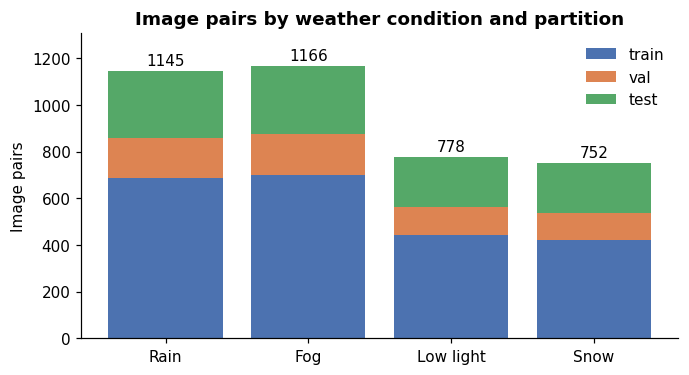

saved /content/drive/MyDrive/iddaw_outputs/figures/F_eda_01_counts.png


In [9]:
# Figure: images per condition and partition
fig, ax = plt.subplots(figsize=(7, 3.6))
ct = pd.crosstab(df.condition, df.study_split).reindex(COND_ORDER)[["train", "val", "test"]]
bottom = np.zeros(len(ct))
for s, col in zip(["train", "val", "test"], ["#4C72B0", "#DD8452", "#55A868"]):
    ax.bar([COND_NAME[c] for c in ct.index], ct[s], bottom=bottom, label=s, color=col); bottom += ct[s].values
for i, v in enumerate(bottom): ax.text(i, v + bottom.max() * 0.02, int(v), ha="center")
ax.set_ylim(0, bottom.max() * 1.12)
ax.axhline(0, color="k", lw=.5); ax.set_ylabel("Image pairs"); ax.set_title("Image pairs by weather condition and partition"); ax.legend(frameon=False)
savefig(fig, "F_eda_01_counts")

**Observations**

- All four conditions keep the same train/val/test proportions, so results by condition are comparable.
- Snow and low light have the smallest training sets (421 and 444 images).

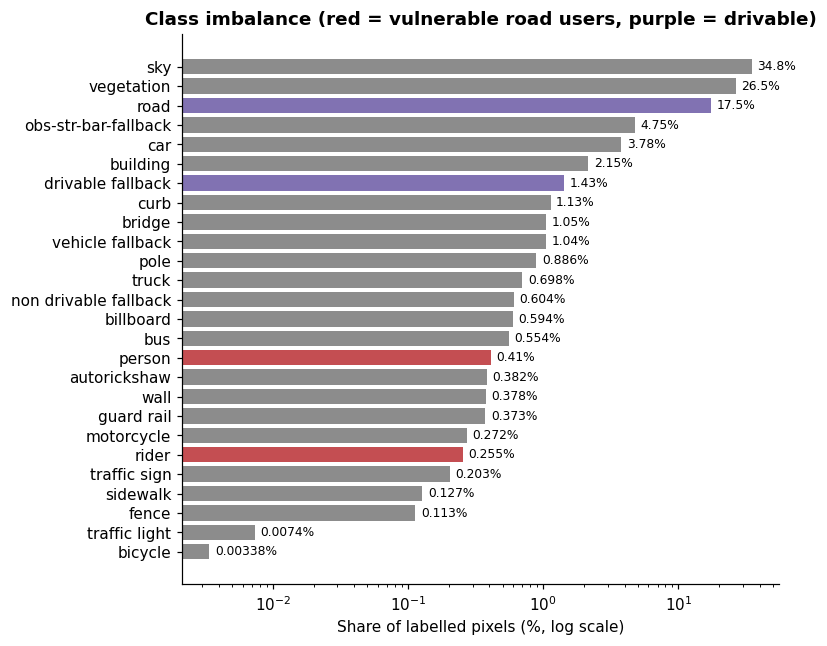

saved /content/drive/MyDrive/iddaw_outputs/figures/F_eda_02_class_share.png


In [10]:
# Figure: class pixel share (log scale) -> class imbalance
px = df[PX].sum().values.astype(float); share = px / px.sum() * 100
order = np.argsort(share)
fig, ax = plt.subplots(figsize=(7, 6.5))
cols = ["#C44E52" if i in VRU else ("#8172B2" if i in DRIVABLE else "#8C8C8C") for i in order]
ax.barh([CLASSES[i] for i in order], share[order], color=cols); ax.set_xscale("log")
for y, i in enumerate(order): ax.text(share[i] * 1.1, y, f"{share[i]:.3g}%", va="center", fontsize=8)
ax.set_xlabel("Share of labelled pixels (%, log scale)"); ax.set_title("Class imbalance (red = vulnerable road users, purple = drivable)")
savefig(fig, "F_eda_02_class_share")
pd.DataFrame({"class": CLASSES, "pixel_share_pct": share.round(4)}).sort_values("pixel_share_pct", ascending=False).to_csv(os.path.join(TAB_DIR, "T_class_share.csv"), index=False)

**Observations**

- Sky (34.8%), vegetation (26.5%) and road (17.5%) make up about **79%** of all pixels.
- Person (0.41%) and rider (0.26%) are tiny, and **bicycle (0.003%)** is about 10,000 times rarer than sky.
- Plain cross-entropy will favour the large classes, so results must be reported per class, not only as mIoU.

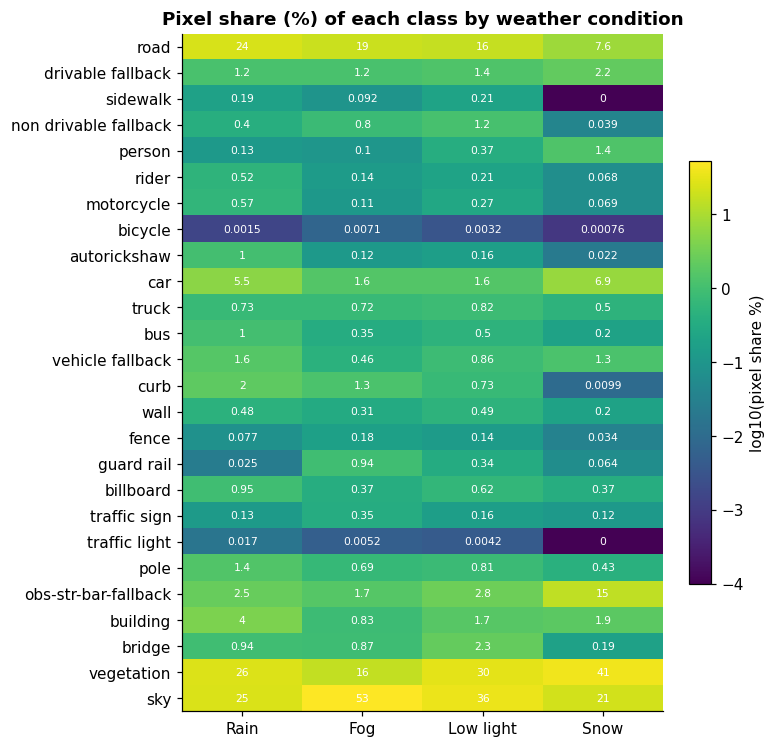

saved /content/drive/MyDrive/iddaw_outputs/figures/F_eda_03_class_by_condition.png


In [11]:
# Figure: class share by condition (heatmap of log10 share)
cs = df.groupby("condition")[PX].sum().reindex(COND_ORDER); cs = cs.div(cs.sum(1), axis=0) * 100
fig, ax = plt.subplots(figsize=(6.2, 8))
im = ax.imshow(np.log10(cs.T.values + 1e-4), aspect="auto", cmap="viridis")
ax.set_yticks(range(NC)); ax.set_yticklabels(CLASSES); ax.set_xticks(range(4)); ax.set_xticklabels([COND_NAME[c] for c in COND_ORDER])
for i in range(NC):
    for j in range(4): ax.text(j, i, f"{cs.T.values[i, j]:.2g}", ha="center", va="center", fontsize=7, color="w")
cb = plt.colorbar(im, ax=ax, fraction=.04); cb.set_label("log10(pixel share %)")
ax.set_title("Pixel share (%) of each class by weather condition")
savefig(fig, "F_eda_03_class_by_condition")

**Observations**

- Fog images are **53% sky**, which leaves fewer useful pixels per image.
- In snow, road drops to **7.6%** while barriers and fallback structures rise to **15%**; sidewalks and traffic lights almost disappear.
- The scene layout changes with the weather, which is why every result is reported per condition (RQ1).

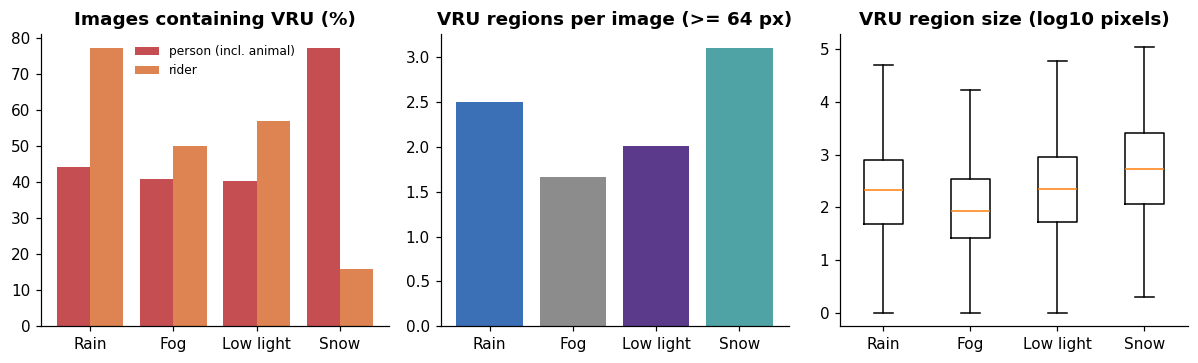

saved /content/drive/MyDrive/iddaw_outputs/figures/F_eda_04_vru.png
share of VRU regions smaller than 500 px (%): {'RAIN': 67.0, 'FOG': 80.4, 'LOWLIGHT': 64.4, 'SNOW': 49.1}


In [12]:
# Figure: vulnerable road users by condition
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
vr = df.groupby("condition").agg(with_person=("px_4", lambda s: (s > 0).mean() * 100), with_rider=("px_5", lambda s: (s > 0).mean() * 100),
                                 regions=("n_vru_regions", "mean")).reindex(COND_ORDER)
x = np.arange(4)
axs[0].bar(x - .2, vr.with_person, .4, label="person (incl. animal)", color="#C44E52"); axs[0].bar(x + .2, vr.with_rider, .4, label="rider", color="#DD8452")
axs[0].set_title("Images containing VRU (%)"); axs[0].legend(frameon=False, fontsize=8)
axs[1].bar(x, vr.regions, color=[COND_COLOR[c] for c in COND_ORDER]); axs[1].set_title(f"VRU regions per image (>= {MIN_MISS_AREA} px)")
areas = {c: np.concatenate([np.array(a.split(";"), int) for a in df.loc[df.condition == c, "vru_areas"].dropna() if a]) for c in COND_ORDER}
axs[2].boxplot([np.log10(areas[c][areas[c] > 0] if len(areas[c]) else [1]) for c in COND_ORDER], showfliers=False)
axs[2].set_title("VRU region size (log10 pixels)")
for a in axs[:2]: a.set_xticks(x); a.set_xticklabels([COND_NAME[c] for c in COND_ORDER])
axs[2].set_xticklabels([COND_NAME[c] for c in COND_ORDER])
fig.tight_layout(); savefig(fig, "F_eda_04_vru")
small = {c: float((areas[c] < 500).mean() * 100) if len(areas[c]) else np.nan for c in COND_ORDER}
print("share of VRU regions smaller than 500 px (%):", {k: round(v, 1) for k, v in small.items()})

**Observations**

- Riders dominate rain images (about 78%), while persons dominate snow images (78%; riders only 16%).
- Most people regions are small: **80% of those in fog are under 500 pixels** (49% in snow).
- Small, faint people in fog are the hardest case, which supports keeping 1024×768 resolution.

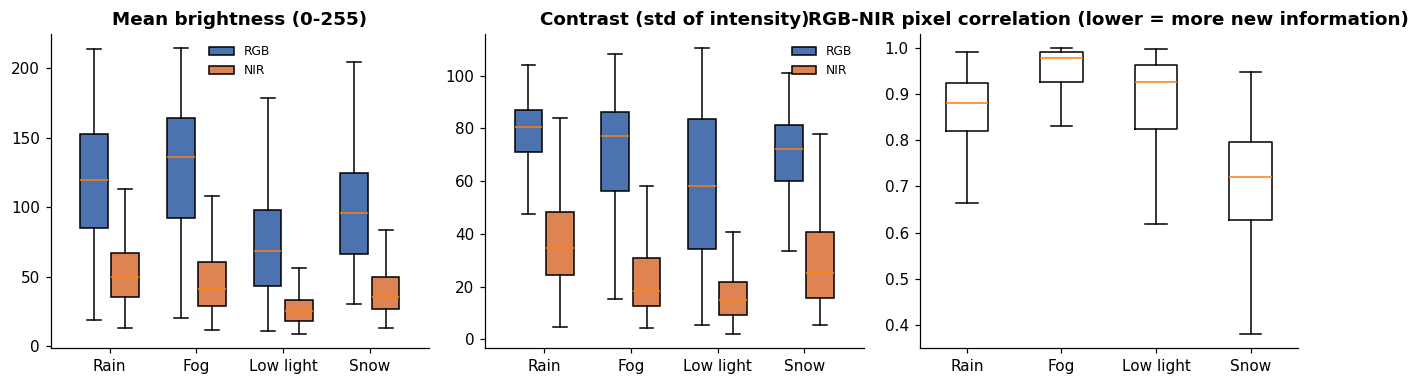

saved /content/drive/MyDrive/iddaw_outputs/figures/F_eda_05_rgb_vs_nir.png


In [13]:
# Figure: brightness and contrast of RGB vs NIR, and RGB-NIR correlation, by condition
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (a, b, t) in zip(axs[:2], [("rgb_mean", "nir_mean", "Mean brightness (0-255)"), ("rgb_std", "nir_std", "Contrast (std of intensity)")]):
    pos = np.arange(4)
    b1 = ax.boxplot([df.loc[df.condition == c, a] for c in COND_ORDER], positions=pos - .18, widths=.32, patch_artist=True, showfliers=False)
    b2 = ax.boxplot([df.loc[df.condition == c, b] for c in COND_ORDER], positions=pos + .18, widths=.32, patch_artist=True, showfliers=False)
    for p in b1["boxes"]: p.set_facecolor("#4C72B0")
    for p in b2["boxes"]: p.set_facecolor("#DD8452")
    ax.set_xticks(pos); ax.set_xticklabels([COND_NAME[c] for c in COND_ORDER]); ax.set_title(t)
    ax.legend([b1["boxes"][0], b2["boxes"][0]], ["RGB", "NIR"], frameon=False, fontsize=8)
axs[2].boxplot([df.loc[df.condition == c, "rgb_nir_corr"].dropna() for c in COND_ORDER], showfliers=False)
axs[2].set_xticklabels([COND_NAME[c] for c in COND_ORDER]); axs[2].set_title("RGB-NIR pixel correlation (lower = more new information)")
fig.tight_layout(); savefig(fig, "F_eda_05_rgb_vs_nir")

**Observations**

- NIR is darker and lower in contrast than RGB in every condition.
- RGB–NIR correlation is **lowest in snow (0.72)** and **highest in fog (0.98)**, so NIR carries the most new information in snow and almost none in fog.
- Expectation for RQ2: the biggest NIR gain in snow, the smallest in fog.

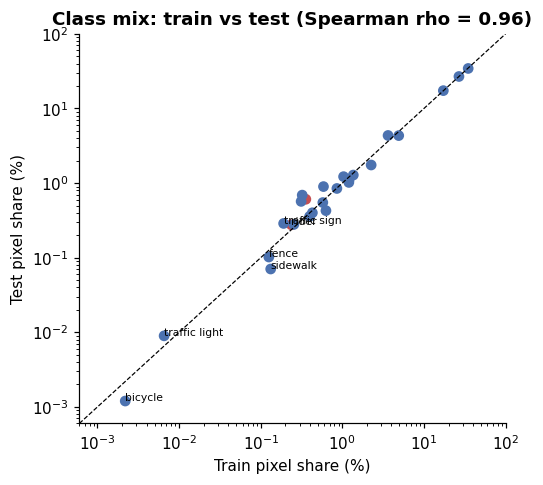

saved /content/drive/MyDrive/iddaw_outputs/figures/F_eda_06_train_vs_test.png


In [14]:
# Figure: train vs test class distribution (representative split check)
tr = TR[PX].sum().values.astype(float); te = TE[PX].sum().values.astype(float)
tr, te = tr / tr.sum() * 100, te / te.sum() * 100
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.scatter(tr, te, c=["#C44E52" if i in VRU else "#4C72B0" for i in range(NC)])
lim = [max(1e-4, min(tr[tr > 0].min(), te[te > 0].min()) / 2), 100]
ax.plot(lim, lim, "k--", lw=.8); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
for i in np.argsort(tr)[:6]: ax.annotate(CLASSES[i], (tr[i], te[i]), fontsize=7)
ax.set_xlabel("Train pixel share (%)"); ax.set_ylabel("Test pixel share (%)")
r = stats.spearmanr(tr, te).correlation; ax.set_title(f"Class mix: train vs test (Spearman rho = {r:.2f})")
savefig(fig, "F_eda_06_train_vs_test")

**Observations**

- The train and test class mixes match closely (**Spearman ρ = 0.96**), so the test set is representative.
- Only the rarest classes (bicycle, traffic light) differ, because they appear in very few images.

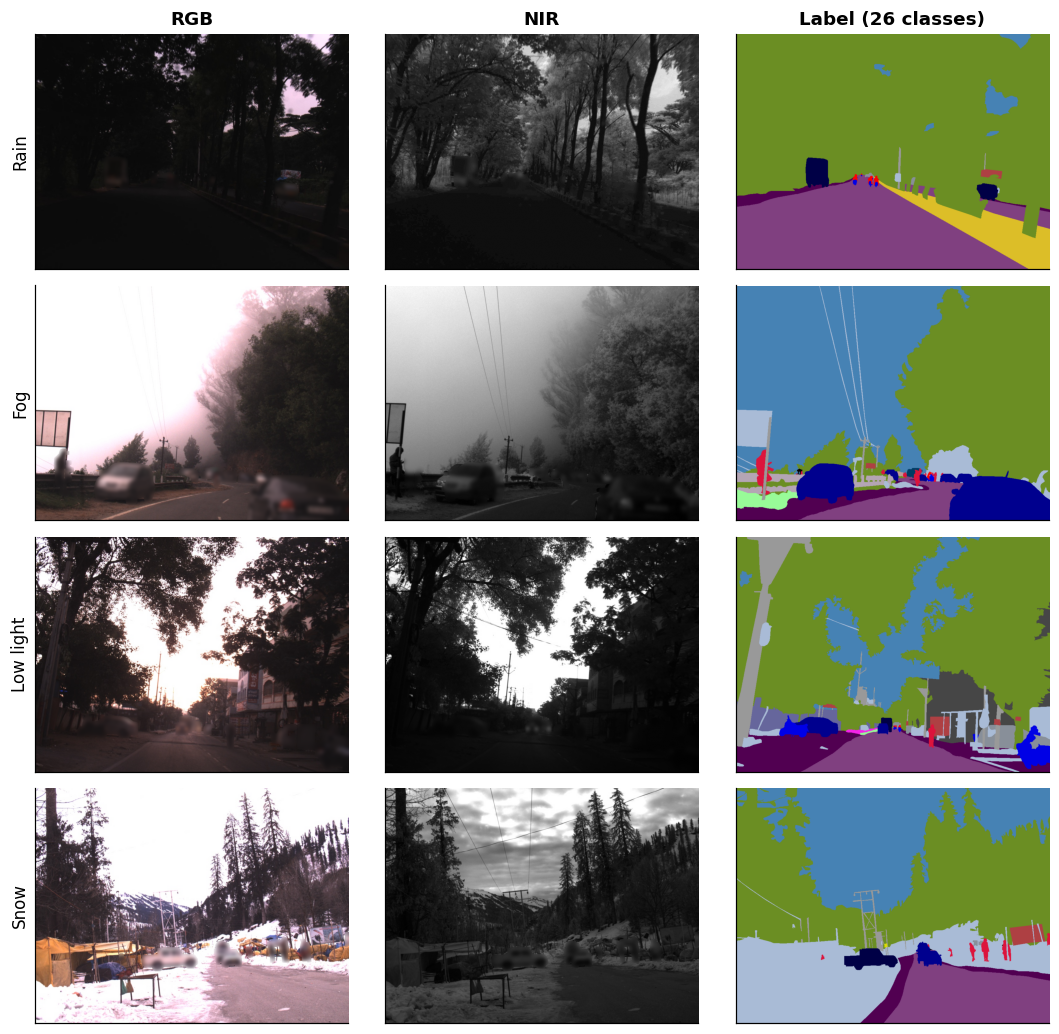

saved /content/drive/MyDrive/iddaw_outputs/figures/F_eda_07_examples.png


In [15]:
# Figure: one anonymised example per condition (people and vehicles blurred using the ground-truth mask)
def anonymise(img, m, k=41):
    region = np.isin(m, VRU + VEHICLE_IDS).astype(np.uint8)
    region = cv2.dilate(region, np.ones((9, 9), np.uint8)) > 0
    blur = cv2.GaussianBlur(img, (k, k), 0); out = img.copy(); out[region] = blur[region]; return out
rng_s = np.random.RandomState(SEED)
fig, axs = plt.subplots(4, 3, figsize=(10, 9.5))
for r_, c in enumerate(COND_ORDER):
    cand = df[(df.condition == c) & (df.has_vru == 1)]; cand = cand if len(cand) else df[df.condition == c]
    row = cand.iloc[rng_s.randint(len(cand))]
    m = read_mask(row.mask_path)
    for k_, (im_, t) in enumerate([(anonymise(read_rgb(row.rgb_path), m), "RGB"), (anonymise(read_gray(row.nir_path), m), "NIR"), (PALETTE[m], "Label (26 classes)")]):
        axs[r_, k_].imshow(im_, cmap="gray" if im_.ndim == 2 else None); axs[r_, k_].set_xticks([]); axs[r_, k_].set_yticks([])
        if r_ == 0: axs[r_, k_].set_title(t)
    axs[r_, 0].set_ylabel(COND_NAME[c], fontsize=11)
fig.tight_layout(); savefig(fig, "F_eda_07_examples")

**Observations**

- People and vehicles are **blurred automatically** using the label masks, as the dataset license requires.
- The examples show how each weather type reduces visibility, especially in low light and fog.

In [16]:
# Normalisation statistics from TRAINING images only (avoids leakage)
NIR_MEAN = float(TR.nir_mean.mean() / 255); NIR_STD = float(np.sqrt((TR.nir_std ** 2 + TR.nir_mean ** 2).mean() - TR.nir_mean.mean() ** 2) / 255)
CLASS_FREQ_TRAIN = (TR[PX].sum() / TR[PX].sum().sum()).values
json.dump({"NIR_MEAN": NIR_MEAN, "NIR_STD": NIR_STD}, open(os.path.join(OUT_DIR, "nir_norm.json"), "w"))
print("NIR mean/std (0-1 scale):", round(NIR_MEAN, 4), round(NIR_STD, 4))

NIR mean/std (0-1 scale): 0.1645 0.1621


**Observations**

- NIR mean / standard deviation (**0.164 / 0.162**) were computed from **training images only**, to avoid test-data leakage.
- RGB uses the standard ImageNet statistics that match the pretrained encoder.

## 6. Evaluation functions and naive baselines
Metrics: per-class IoU and mIoU; Safe IoU and SmIoU (official IDD-AW definition); per-image mIoU/SmIoU over classes present in
the ground truth; VRU pixel miss rate (VRU pixels predicted as drivable); image-level dangerous miss (a connected region of at least
`MIN_MISS_AREA` VRU pixels predicted as drivable).

In [17]:
def image_metrics(gt, pred):
    valid = gt != IGNORE
    hist = np.bincount(NC * gt[valid].astype(np.int64) + pred[valid].astype(np.int64), minlength=NC * NC).reshape(NC, NC)
    iou, siou = iou_and_safe_iou(hist)
    present = hist.sum(1) > 0
    vru_gt = np.isin(gt, VRU); miss = vru_gt & np.isin(pred, DRIVABLE)
    n, _, st_, _ = cv2.connectedComponentsWithStats(miss.astype(np.uint8), connectivity=8)
    big_miss = int((st_[1:, cv2.CC_STAT_AREA] >= MIN_MISS_AREA).any()) if n > 1 else 0
    return hist, {"miou_img": np.nanmean(iou[present]), "smiou_img": np.nanmean(siou[present]),
                  "vru_pixels": int(vru_gt.sum()), "vru_miss_pixels": int(miss.sum()), "vru_miss_img": big_miss}

def evaluate(name, pred_fn, data, batch_pred=None):
    """pred_fn(row) -> HxW uint8 prediction. Saves per-image CSV and per-condition confusion matrices."""
    f_csv = os.path.join(OUT_DIR, "eval", f"{name}_per_image.csv"); f_h = os.path.join(OUT_DIR, "eval", f"{name}_hist.npz")
    os.makedirs(os.path.dirname(f_csv), exist_ok=True)
    if os.path.exists(f_csv) and os.path.exists(f_h):
        return pd.read_csv(f_csv), dict(np.load(f_h))
    rows, hists = [], {c: np.zeros((NC, NC), np.int64) for c in COND_ORDER}
    preds = batch_pred(data) if batch_pred else (pred_fn(r) for r in data.itertuples())
    for r, pred in zip(data.itertuples(), preds):
        gt = read_mask(r.mask_path)
        h_, m_ = image_metrics(gt, pred); hists[r.condition] += h_
        rows.append({"image_id": r.image_id, "condition": r.condition, "split_group": r.split_group, "has_vru": r.has_vru, **m_})
    out = pd.DataFrame(rows); out.to_csv(f_csv, index=False); np.savez(f_h, **hists)
    return out, hists

def summarise(name, per_img, hists):
    rows = []
    for c in COND_ORDER + ["ALL"]:
        h_ = sum(hists.values()) if c == "ALL" else hists[c]
        iou, siou = iou_and_safe_iou(h_)
        sub = per_img if c == "ALL" else per_img[per_img.condition == c]
        v = sub[sub.has_vru == 1]
        rows.append({"model": name, "condition": c, "n_images": len(sub), "mIoU": np.nanmean(iou) * 100, "SmIoU": np.nanmean(siou) * 100,
                     "gap": (np.nanmean(iou) - np.nanmean(siou)) * 100,
                     "VRU_pixel_miss_rate_pct": sub.vru_miss_pixels.sum() / max(1, sub.vru_pixels.sum()) * 100,
                     "images_with_dangerous_miss_pct": v.vru_miss_img.mean() * 100 if len(v) else np.nan})
    return pd.DataFrame(rows)

TEST = TE if EVAL_LIMIT is None else TE.groupby("condition").head(EVAL_LIMIT // 4).reset_index(drop=True)
print("test images used for evaluation:", len(TEST))

# Naive baseline 1: majority class everywhere. Naive baseline 2: per-pixel location prior (most frequent training class at each pixel).
maj = int(np.argmax(CLASS_FREQ_TRAIN))
prior_f = os.path.join(OUT_DIR, "location_prior.npy")
if os.path.exists(prior_f):
    prior = np.load(prior_f)
else:
    hs, ws = IMG_H // 4, IMG_W // 4; acc = np.zeros(NC * hs * ws, np.int64); base = np.arange(hs * ws)
    for p in TR.mask_path:
        m = cv2.resize(read_mask(p), (ws, hs), interpolation=cv2.INTER_NEAREST).ravel(); ok = m != IGNORE
        acc += np.bincount(m[ok].astype(np.int64) * hs * ws + base[ok], minlength=NC * hs * ws)
    prior = cv2.resize(acc.reshape(NC, hs, ws).argmax(0).astype(np.uint8), (IMG_W, IMG_H), interpolation=cv2.INTER_NEAREST)
    np.save(prior_f, prior)
results = {}
for name, fn in [("naive_majority", lambda r: np.full((IMG_H, IMG_W), maj, np.uint8)), ("naive_location_prior", lambda r: prior)]:
    results[name] = evaluate(name, fn, TEST)
summ_all = pd.concat([summarise(k, *v) for k, v in results.items()])
display(summ_all.round(2))

test images used for evaluation: 1013


,model,condition,n_images,mIoU,SmIoU,gap,VRU_pixel_miss_rate_pct,images_with_dangerous_miss_pct
0,naive_majority,RAIN,287,0.98,-29.79,30.77,0.00,0.00
1,naive_majority,FOG,292,1.94,-28.83,30.77,0.00,0.00
2,naive_majority,LOWLIGHT,217,1.52,-29.25,30.77,0.00,0.00
3,naive_majority,SNOW,217,0.85,-29.59,30.43,0.00,0.00
4,naive_majority,ALL,1013,1.32,-29.45,30.77,0.00,0.00
0,naive_location_prior,RAIN,287,5.79,-24.98,30.77,10.32,20.85
1,naive_location_prior,FOG,292,6.78,-23.99,30.77,39.36,76.57
2,naive_location_prior,LOWLIGHT,217,5.81,-24.96,30.77,86.71,92.62
3,naive_location_prior,SNOW,217,4.17,-26.27,30.43,59.74,81.77
4,naive_location_prior,ALL,1013,5.67,-25.10,30.77,56.97,63.65


**Observations**

- Naive baselines score only **1.3% (majority class)** and **5.7% (location prior)** mIoU on the 1,013 test images.
- Both have **negative SmIoU (about −25 to −29)**, because the official safety metric subtracts more for dangerous errors than it credits for correct pixels.
- The location prior calls **57% of people pixels "road"**; this is the floor every trained model must beat.

## 7. SegFormer-B2 training
* **Model 1 `rgb_ce`** – RGB input, cross-entropy (main baseline, RQ1).
* **Model 2 `rgbn_ce`** – RGB+NIR early fusion (4-channel input), cross-entropy (RQ2).
* **Model 3 `rgb_td`** – RGB input, cross-entropy + tree-distance penalty (hierarchy-aware loss, RQ3).

Same seed, crops, augmentation, schedule, and step budget for all three, so input or loss is the only difference.
Checkpoints are saved to Drive every `CKPT_EVERY` steps and training resumes automatically.

In [18]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import SegformerForSemanticSegmentation
DEV = "cuda" if torch.cuda.is_available() else "cpu"
RGB_MEAN = np.array([0.485, 0.456, 0.406], np.float32); RGB_STD = np.array([0.229, 0.224, 0.225], np.float32)
W_T = torch.tensor(W, dtype=torch.float32, device=DEV)
MODEL_DIR = os.path.join(OUT_DIR, "models_v2")

class IDDAW(Dataset):
    def __init__(self, data, mode, train):
        self.d, self.mode, self.train = data.reset_index(drop=True), mode, train
    def __len__(self): return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        img = read_rgb(r.rgb_path).astype(np.float32) / 255.0
        if self.mode == "rgbn":
            img = np.dstack([img, read_gray(r.nir_path).astype(np.float32) / 255.0])
        m = read_mask(r.mask_path)
        if self.train:
            s = random.uniform(0.75, 1.5)
            img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
            m = cv2.resize(m, None, fx=s, fy=s, interpolation=cv2.INTER_NEAREST)
            if img.ndim == 2: img = img[..., None]
            ph, pw = max(0, CROP - img.shape[0]), max(0, CROP - img.shape[1])
            if ph or pw:
                img = np.pad(img, ((0, ph), (0, pw), (0, 0))); m = np.pad(m, ((0, ph), (0, pw)), constant_values=IGNORE)
            y0, x0 = random.randint(0, img.shape[0] - CROP), random.randint(0, img.shape[1] - CROP)
            img, m = img[y0:y0 + CROP, x0:x0 + CROP], m[y0:y0 + CROP, x0:x0 + CROP]
            if random.random() < 0.5: img, m = img[:, ::-1], m[:, ::-1]
            a, b = random.uniform(0.8, 1.2), random.uniform(-0.08, 0.08)          # brightness/contrast jitter (RGB only)
            img[..., :3] = np.clip(img[..., :3] * a + b, 0, 1)
        img = img.copy(); img[..., :3] = (img[..., :3] - RGB_MEAN) / RGB_STD
        if self.mode == "rgbn": img[..., 3] = (img[..., 3] - NIR_MEAN) / NIR_STD
        return torch.from_numpy(img.transpose(2, 0, 1).copy()), torch.from_numpy(m.astype(np.int64).copy())

from transformers import SegformerConfig

def widen_first_conv(model):
    """Early fusion: replace the first 3-channel convolution (first patch embedding) with a 4-channel one.
    The NIR filter is initialised as the mean of the pretrained RGB filters. Works across transformers versions."""
    for name, mod in model.named_modules():
        if isinstance(mod, nn.Conv2d) and mod.in_channels == 3:
            new = nn.Conv2d(4, mod.out_channels, kernel_size=mod.kernel_size, stride=mod.stride,
                            padding=mod.padding, bias=mod.bias is not None)
            with torch.no_grad():
                new.weight[:, :3] = mod.weight; new.weight[:, 3:] = mod.weight.mean(1, keepdim=True)
                if mod.bias is not None: new.bias.copy_(mod.bias)
            parent_name, _, attr = name.rpartition(".")
            parent = model.get_submodule(parent_name) if parent_name else model
            setattr(parent, attr, new)
            return name
    raise RuntimeError("no 3-channel convolution found")

def build_model(mode):
    cfg = SegformerConfig.from_pretrained("nvidia/mit-b2")
    cfg.id2label = {i: c for i, c in enumerate(CLASSES)}; cfg.label2id = {c: i for i, c in enumerate(CLASSES)}
    cfg.num_labels = NC
    model = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b2", config=cfg, ignore_mismatched_sizes=True)
    if mode == "rgbn":
        layer = widen_first_conv(model); model.config.num_channels = 4
        print("early fusion: widened", layer, "to 4 input channels")
    with torch.no_grad():   # sanity check: correct number of input channels and 26 output classes
        out = model(pixel_values=torch.zeros(1, 4 if mode == "rgbn" else 3, 64, 64)).logits
    assert out.shape[1] == NC, f"model outputs {out.shape[1]} classes, expected {NC}"
    return model

def seg_loss(logits, y, use_td):
    logits = F.interpolate(logits, size=y.shape[-2:], mode="bilinear", align_corners=False).float()
    ce = F.cross_entropy(logits, y, ignore_index=IGNORE)
    if not use_td: return ce, ce.detach(), torch.zeros((), device=y.device)
    valid = y != IGNORE
    p = logits.softmax(1).permute(0, 2, 3, 1)[valid]          # (N, C) probabilities of labelled pixels
    pen = (p * W_T[y[valid]]).sum(1).mean()                    # expected tree-distance cost (0 when correct)
    return ce + TD_LAMBDA * pen, ce.detach(), pen.detach()

@torch.no_grad()
def predict_batch(model, data, mode, bs=4):
    model.eval(); ds = IDDAW(data, mode, train=False)
    dl = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=2)
    for x, _ in dl:
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEV == "cuda"):
            lg = model(pixel_values=x.to(DEV)).logits
        lg = F.interpolate(lg.float(), size=(IMG_H, IMG_W), mode="bilinear", align_corners=False)
        for p in lg.argmax(1).byte().cpu().numpy(): yield p

def quick_val_miou(model, mode):
    hist = np.zeros((NC, NC), np.int64); sub = VA.sample(min(VAL_MONITOR, len(VA)), random_state=SEED)
    for r, p in zip(sub.itertuples(), predict_batch(model, sub, mode)):
        hist += image_metrics(read_mask(r.mask_path), p)[0]
    iou, siou = iou_and_safe_iou(hist); model.train(); return np.nanmean(iou) * 100, np.nanmean(siou) * 100

def train(name):
    mode = "rgbn" if name.startswith("rgbn") else "rgb"; use_td = name.endswith("_td")
    d = os.path.join(MODEL_DIR, name); os.makedirs(d, exist_ok=True)
    final, last, logf = os.path.join(d, "final.pt"), os.path.join(d, "last.pt"), os.path.join(d, "train_log.csv")
    if os.path.exists(final): print(name, "already trained"); return
    set_seed(SEED)
    model = build_model(mode).to(DEV).train()
    head = [p for n, p in model.named_parameters() if n.startswith("decode_head")]
    enc = [p for n, p in model.named_parameters() if not n.startswith("decode_head")]
    opt = torch.optim.AdamW([{"params": enc, "lr": LR}, {"params": head, "lr": LR * 10}], weight_decay=0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / WARMUP) * max(0.0, 1 - s / STEPS) ** 1.0)
    scaler = torch.amp.GradScaler("cuda", enabled=DEV == "cuda")
    step, log = 0, []
    if os.path.exists(last):
        ck = torch.load(last, map_location=DEV, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        step, log = ck["step"], ck["log"]; random.setstate(ck["py_rng"]); np.random.set_state(ck["np_rng"]); torch.set_rng_state(ck["torch_rng"].cpu())
        print(f"resumed {name} at step {step}")
    bs = BATCH
    def loader(bs):
        return DataLoader(IDDAW(TR, mode, train=True), batch_size=bs, shuffle=True, num_workers=2, drop_last=True,
                          pin_memory=DEV == "cuda", persistent_workers=True)
    dl = loader(bs); t0, s0 = time.time(), step
    while step < STEPS:
        for x, y in dl:
            if step >= STEPS: break
            x, y = x.to(DEV, non_blocking=True), y.to(DEV, non_blocking=True)
            try:
                with torch.autocast("cuda", dtype=torch.float16, enabled=DEV == "cuda"):
                    logits = model(pixel_values=x).logits
                loss, ce, pen = seg_loss(logits, y, use_td)
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
            except torch.cuda.OutOfMemoryError:
                opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                if bs <= 2: raise
                bs //= 2; print("out of memory -> batch size", bs); dl = loader(bs); break
            step += 1
            if step % 50 == 0 or step == STEPS:
                el = time.time() - t0; eta = el / max(1, step - s0) * (STEPS - step) / 3600
                rec = {"step": step, "loss": loss.item(), "ce": ce.item(), "td_penalty": pen.item(), "lr": sched.get_last_lr()[0], "batch": bs}
                log.append(rec); print(f"{name} step {step}/{STEPS} loss {rec['loss']:.4f} | ETA {eta:.2f} h")
            if step % EVAL_EVERY == 0 or step == STEPS:
                mi, smi = quick_val_miou(model, mode); log.append({"step": step, "val_mIoU": mi, "val_SmIoU": smi})
                print(f"   validation ({VAL_MONITOR} images): mIoU {mi:.2f}  SmIoU {smi:.2f}")
            if step % CKPT_EVERY == 0 or step == STEPS:
                tmp = last + ".tmp"
                torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                            "step": step, "log": log, "py_rng": random.getstate(), "np_rng": np.random.get_state(),
                            "torch_rng": torch.get_rng_state()}, tmp)
                os.replace(tmp, last)
    pd.DataFrame(log).to_csv(logf, index=False)
    torch.save(model.state_dict(), final)
    print(f"{name} finished: {step} steps, {(time.time()-t0)/3600:.2f} h this session")

In [19]:
for name in MODELS:
    train(name)

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 99.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 98.9MB            

...

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             

early fusion: widened segformer.stages.0.patch_embeddings.proj to 4 input channels
rgbn_ce step 50/8000 loss 1.8316 | ETA 1.25 h
rgbn_ce step 100/8000 loss 1.1362 | ETA 1.22 h
rgbn_ce step 150/8000 loss 0.3813 | ETA 1.20 h
rgbn_ce step 200/8000 loss 0.3291 | ETA 1.19 h
rgbn_ce step 250/8000 loss 0.7432 | ETA 1.18 h
rgbn_ce step 300/8000 loss 0.4109 | ETA 1.18 h
rgbn_ce step 350/8000 loss 0.4355 | ETA 1.17 h
rgbn_ce step 400/8000 loss 0.3314 | ETA 1.16 h
rgbn_ce step 450/8000 loss 0.3920 | ETA 1.15 h
rgbn_ce step 500/8000 loss 0.3109 | ETA 1.14 h
rgbn_ce step 550/8000 loss 0.5977 | ETA 1.13 h
rgbn_ce step 600/8000 loss 0.3980 | ETA 1.13 h
rgbn_ce step 650/8000 loss 0.1872 | ETA 1.12 h
rgbn_ce step 700/8000 loss 0.3686 | ETA 1.11 h
rgbn_ce step 750/8000 loss 0.2490 | ETA 1.10 h
rgbn_ce step 800/8000 loss 0.4249 | ETA 1.09 h
rgbn_ce step 850/8000 loss 0.4511 | ETA 1.08 h
rgbn_ce step 900/8000 loss 0.3356 | ETA 1.07 h
rgbn_ce step 950/8000 loss 0.2737 | ETA 1.07 h
rgbn_ce step 1000/8000 lo

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             

rgb_td step 50/8000 loss 2.6220 | ETA 1.39 h
rgb_td step 100/8000 loss 1.4863 | ETA 1.35 h
rgb_td step 150/8000 loss 0.8985 | ETA 1.33 h
rgb_td step 200/8000 loss 0.5975 | ETA 1.32 h
rgb_td step 250/8000 loss 0.6169 | ETA 1.31 h
rgb_td step 300/8000 loss 0.9066 | ETA 1.30 h
rgb_td step 350/8000 loss 0.4938 | ETA 1.29 h
rgb_td step 400/8000 loss 0.4146 | ETA 1.28 h
rgb_td step 450/8000 loss 0.5789 | ETA 1.27 h
rgb_td step 500/8000 loss 0.4146 | ETA 1.26 h
rgb_td step 550/8000 loss 0.3971 | ETA 1.28 h
rgb_td step 600/8000 loss 0.4174 | ETA 1.27 h
rgb_td step 650/8000 loss 0.8741 | ETA 1.25 h
rgb_td step 700/8000 loss 0.2680 | ETA 1.24 h
rgb_td step 750/8000 loss 0.4168 | ETA 1.23 h
rgb_td step 800/8000 loss 0.3949 | ETA 1.22 h
rgb_td step 850/8000 loss 0.5040 | ETA 1.21 h
rgb_td step 900/8000 loss 0.5948 | ETA 1.20 h
rgb_td step 950/8000 loss 0.4248 | ETA 1.19 h
rgb_td step 1000/8000 loss 0.5131 | ETA 1.18 h
   validation (120 images): mIoU 39.90  SmIoU 28.32
rgb_td step 1050/8000 loss 0

**Observations**

- All three models trained for the full **8,000 steps**: Model 1 in 1.08 h, Model 2 in 1.23 h, Model 3 in 1.37 h (about 3.7 h in total on one T4).
- Validation mIoU rose steadily (Model 1: 44.8 → 49.8; Model 3 reached 50.5), so all models learned well.
- Training resumed correctly after a Colab disconnect (from step 1,000), confirming the checkpointing works.

## 8. Evaluation on the held-out test set

In [20]:
def load_trained(name):
    mode = "rgbn" if name.startswith("rgbn") else "rgb"
    m = build_model(mode); m.load_state_dict(torch.load(os.path.join(MODEL_DIR, name, "final.pt"), map_location=DEV)); return m.to(DEV), mode
for name in MODELS:
    if not os.path.exists(os.path.join(MODEL_DIR, name, "final.pt")): print("skip (not trained):", name); continue
    f_csv = os.path.join(OUT_DIR, "eval", f"{name}_per_image.csv")
    if os.path.exists(f_csv): results[name] = evaluate(name, None, TEST); continue
    model, mode = load_trained(name); t = time.time()
    results[name] = evaluate(name, None, TEST, batch_pred=lambda data: predict_batch(model, data, mode))
    print(f"{name} evaluated on {len(TEST)} images in {time.time()-t:.0f}s"); del model; torch.cuda.empty_cache()
summ_all = pd.concat([summarise(k, *v) for k, v in results.items()])
savetab(summ_all.round(2), "T_results_by_model_condition")
overall = summ_all[summ_all.condition == "ALL"].set_index("model")[["mIoU", "SmIoU", "gap", "VRU_pixel_miss_rate_pct", "images_with_dangerous_miss_pct"]]
savetab(overall.round(2).reset_index(), "T_model_comparison_overall")

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             

rgb_ce evaluated on 1013 images in 103s


Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             

...

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             

rgb_td evaluated on 1013 images in 97s


,model,condition,n_images,mIoU,SmIoU,gap,VRU_pixel_miss_rate_pct,images_with_dangerous_miss_pct
0,naive_majority,RAIN,287,0.98,-29.79,30.77,0.00,0.00
1,naive_majority,FOG,292,1.94,-28.83,30.77,0.00,0.00
2,naive_majority,LOWLIGHT,217,1.52,-29.25,30.77,0.00,0.00
3,naive_majority,SNOW,217,0.85,-29.59,30.43,0.00,0.00
4,naive_majority,ALL,1013,1.32,-29.45,30.77,0.00,0.00
0,naive_location_prior,RAIN,287,5.79,-24.98,30.77,10.32,20.85
1,naive_location_prior,FOG,292,6.78,-23.99,30.77,39.36,76.57
2,naive_location_prior,LOWLIGHT,217,5.81,-24.96,30.77,86.71,92.62
3,naive_location_prior,SNOW,217,4.17,-26.27,30.43,59.74,81.77
4,naive_location_prior,ALL,1013,5.67,-25.10,30.77,56.97,63.65


,model,mIoU,SmIoU,gap,VRU_pixel_miss_rate_pct,images_with_dangerous_miss_pct
0,naive_majority,1.32,-29.45,30.77,0.00,0.00
1,naive_location_prior,5.67,-25.10,30.77,56.97,63.65
2,rgb_ce,56.95,48.81,8.14,1.25,17.71
3,rgbn_ce,57.51,49.51,8.00,1.11,17.31
4,rgb_td,56.96,48.78,8.18,1.27,19.17


**Observations**

- On the 1,013 test images, Model 1 (RGB) reaches **57.0% mIoU / 48.8% SmIoU**, about **10× the naive baselines**.
- Model 2 (RGB+NIR) is best overall: **57.5% mIoU / 49.5% SmIoU**; Model 3 (tree loss) matches Model 1 (57.0 / 48.8).
- **Snow is the hardest condition** (Model 1: 39.2% mIoU) and fog the easiest (59.2%), the same ranking as in the IDD-AW paper.
- Model 1 loses about **8 points** between mIoU and SmIoU, the share of accuracy lost to unsafe errors; about **18% of images with people** have at least one dangerous miss.

In [21]:
# Per-class IoU on the test set
pc = []
for k, (pi, hs) in results.items():
    iou, siou = iou_and_safe_iou(sum(hs.values()))
    pc.append(pd.DataFrame({"model": k, "class": CLASSES, "IoU": iou * 100, "SafeIoU": siou * 100}))
pc = pd.concat(pc); savetab(pc.pivot(index="class", columns="model", values="IoU").reindex(CLASSES).round(1).reset_index(), "T_per_class_iou")

model,class,naive_location_prior,naive_majority,rgb_ce,rgb_td,rgbn_ce
0,road,60.3,0.0,94.6,94.5,94.6
1,drivable fallback,0.0,0.0,45.1,43.0,44.1
2,sidewalk,0.0,0.0,28.7,28.3,26.9
3,non drivable fallback,0.0,0.0,37.8,38.7,39.6
4,person,0.0,0.0,72.2,71.9,72.8
5,rider,0.0,0.0,57.4,57.0,59.4
6,motorcycle,0.0,0.0,60.6,60.3,62.1
7,bicycle,0.0,0.0,0.0,0.0,0.0
8,autorickshaw,0.0,0.0,73.4,72.9,75.1
9,car,0.0,0.0,79.7,79.6,79.8


**Observations**

- Large classes are learned very well: road and sky **94.6%**, vegetation **89.6%**, car **79.7%**.
- Vulnerable road users are learned reasonably: person **72%**, rider **57–59%**; **bicycle stays at 0%** because it is almost absent from the data.
- NIR fusion helps most on vehicles and riders (truck +3.3, bus +2.8, rider +2.0 points); the tree loss helps wall (+4.4) but loses bridge (−3.9).

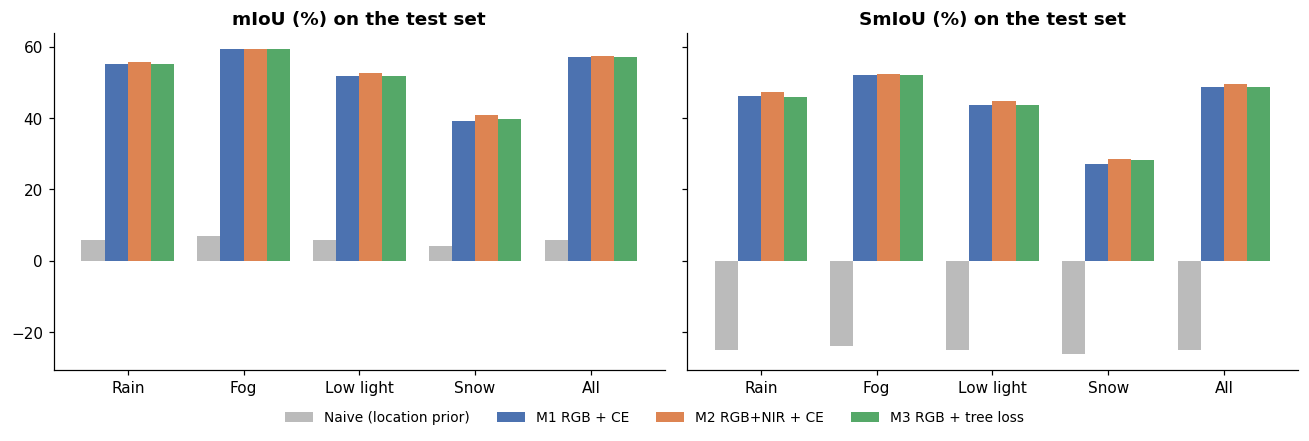

saved /content/drive/MyDrive/iddaw_outputs/figures/F_res_01_by_condition.png


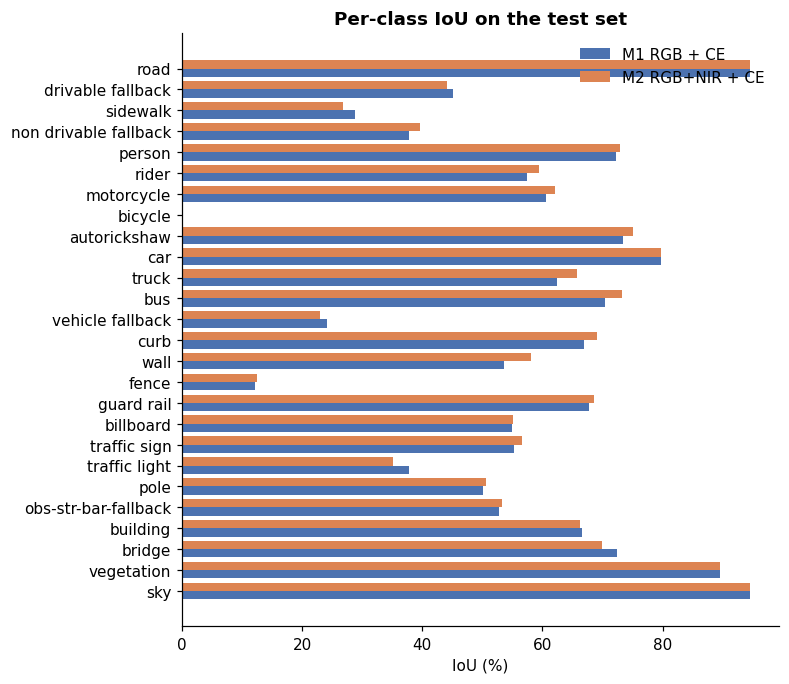

saved /content/drive/MyDrive/iddaw_outputs/figures/F_res_02_per_class.png


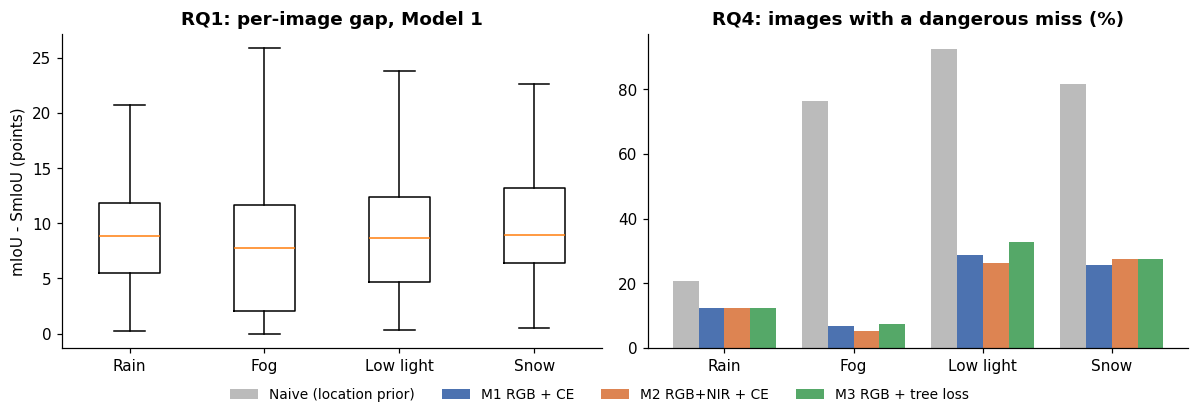

saved /content/drive/MyDrive/iddaw_outputs/figures/F_res_03_gap_and_misses.png


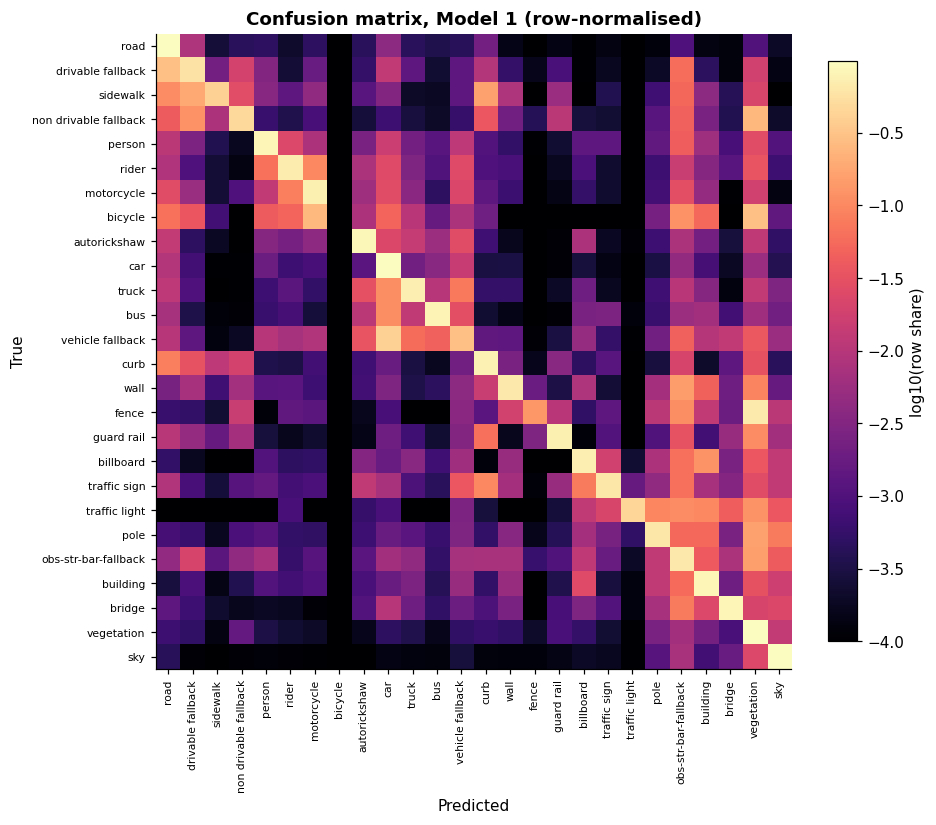

saved /content/drive/MyDrive/iddaw_outputs/figures/F_res_04_confusion.png


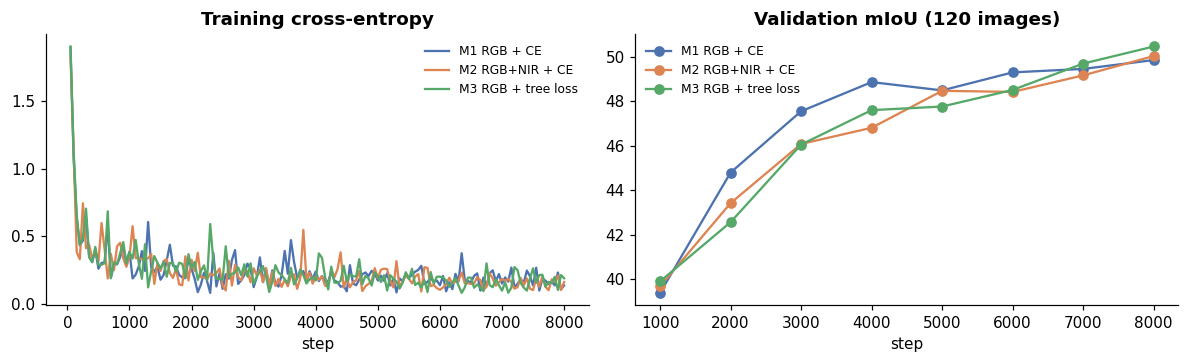

saved /content/drive/MyDrive/iddaw_outputs/figures/F_res_05_training_curves.png


In [22]:
# Figures: model comparison by condition, per-class IoU, gap, dangerous misses
show = [m for m in ["naive_location_prior"] + MODELS if m in results]
colors = {"naive_location_prior": "#BBBBBB", "rgb_ce": "#4C72B0", "rgbn_ce": "#DD8452", "rgb_td": "#55A868"}
label = {"naive_location_prior": "Naive (location prior)", "rgb_ce": "M1 RGB + CE", "rgbn_ce": "M2 RGB+NIR + CE", "rgb_td": "M3 RGB + tree loss"}
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, met in zip(axs, ["mIoU", "SmIoU"]):
    w_ = .8 / len(show)
    for k, m in enumerate(show):
        v = summ_all[summ_all.model == m].set_index("condition").reindex(COND_ORDER + ["ALL"])[met]
        ax.bar(np.arange(5) + (k - (len(show) - 1) / 2) * w_, v, w_, label=label[m], color=colors[m])
    ax.set_xticks(range(5)); ax.set_xticklabels([COND_NAME.get(c, "All") for c in COND_ORDER + ["ALL"]]); ax.set_title(met + " (%) on the test set")
h_l = axs[0].get_legend_handles_labels()
fig.legend(*h_l, loc="lower center", ncol=len(show), frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(); savefig(fig, "F_res_01_by_condition")

if "rgb_ce" in results:
    best = max([m for m in MODELS if m in results], key=lambda m: overall.loc[m, "SmIoU"])
    piv = pc.pivot(index="class", columns="model", values="IoU").reindex(CLASSES)
    fig, ax = plt.subplots(figsize=(7, 7)); y = np.arange(NC)
    ax.barh(y + .2, piv["rgb_ce"], .4, label=label["rgb_ce"], color=colors["rgb_ce"])
    if best != "rgb_ce": ax.barh(y - .2, piv[best], .4, label=label[best], color=colors[best])
    ax.set_yticks(y); ax.set_yticklabels(CLASSES); ax.invert_yaxis(); ax.set_xlabel("IoU (%)"); ax.legend(frameon=False)
    ax.set_title("Per-class IoU on the test set"); savefig(fig, "F_res_02_per_class")

    b = results["rgb_ce"][0]; b["gap"] = b.miou_img - b.smiou_img
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    axs[0].boxplot([b.loc[b.condition == c, "gap"].dropna() * 100 for c in COND_ORDER], showfliers=False)
    axs[0].set_xticklabels([COND_NAME[c] for c in COND_ORDER]); axs[0].set_ylabel("mIoU - SmIoU (points)"); axs[0].set_title("RQ1: per-image gap, Model 1")
    w_ = .8 / len(show)
    for k, m in enumerate(show):
        v = summ_all[summ_all.model == m].set_index("condition").reindex(COND_ORDER)["images_with_dangerous_miss_pct"]
        axs[1].bar(np.arange(4) + (k - (len(show) - 1) / 2) * w_, v, w_, label=label[m], color=colors[m])
    axs[1].set_xticks(range(4)); axs[1].set_xticklabels([COND_NAME[c] for c in COND_ORDER])
    axs[1].set_title("RQ4: images with a dangerous miss (%)")
    fig.legend(*axs[1].get_legend_handles_labels(), loc="lower center", ncol=len(show), frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.06))
    fig.tight_layout(); savefig(fig, "F_res_03_gap_and_misses")

    h_ = sum(results["rgb_ce"][1].values()).astype(float); cm = h_ / np.maximum(h_.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(8.5, 7.5)); im = ax.imshow(np.log10(cm + 1e-4), cmap="magma")
    ax.set_xticks(range(NC)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASSES, fontsize=7)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); plt.colorbar(im, fraction=.04).set_label("log10(row share)")
    ax.set_title("Confusion matrix, Model 1 (row-normalised)"); savefig(fig, "F_res_04_confusion")

# Training curves
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4)); any_log = False
for m in MODELS:
    f = os.path.join(MODEL_DIR, m, "train_log.csv")
    if not os.path.exists(f): continue
    lg = pd.read_csv(f); any_log = True
    l = lg.dropna(subset=["loss"]) if "loss" in lg else lg.iloc[:0]
    v = lg.dropna(subset=["val_mIoU"]) if "val_mIoU" in lg else lg.iloc[:0]
    axs[0].plot(l.step, l.ce, label=label[m], color=colors[m]); axs[1].plot(v.step, v.val_mIoU, "o-", label=label[m], color=colors[m])
axs[0].set_title("Training cross-entropy"); axs[1].set_title(f"Validation mIoU ({VAL_MONITOR} images)")
for a in axs: a.set_xlabel("step"); a.legend(frameon=False, fontsize=8)
fig.tight_layout()
if any_log: savefig(fig, "F_res_05_training_curves")
else: plt.close(fig)

**Observations**

- **Mean IoU by condition:** all three trained models are far above the naive baseline; the differences between them are small (under 2 points in every condition).
- **Per-class chart:** fence, vehicle fallback and bicycle are the weakest classes, all rare or visually mixed.
- **RQ1 gap and RQ4 misses:** snow has the largest gap; low light (26–33%) and snow (26–28%) have the most images with dangerous misses, against 12% in rain and 5–7% in fog.
- **Confusion matrix:** most errors happen between neighbouring classes (rider ↔ person/motorcycle, drivable fallback ↔ road, vehicle fallback ↔ truck/car), which the safety metric penalises less.
- **Training curves:** validation mIoU is still rising at step 8,000, so longer training should improve results in the final report.

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             

Loading weights:   0%|          | 0/364 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b2
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.batch_norm.running_var                      | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.classifier.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.batch_norm.bias                             

early fusion: widened segformer.stages.0.patch_embeddings.proj to 4 input channels


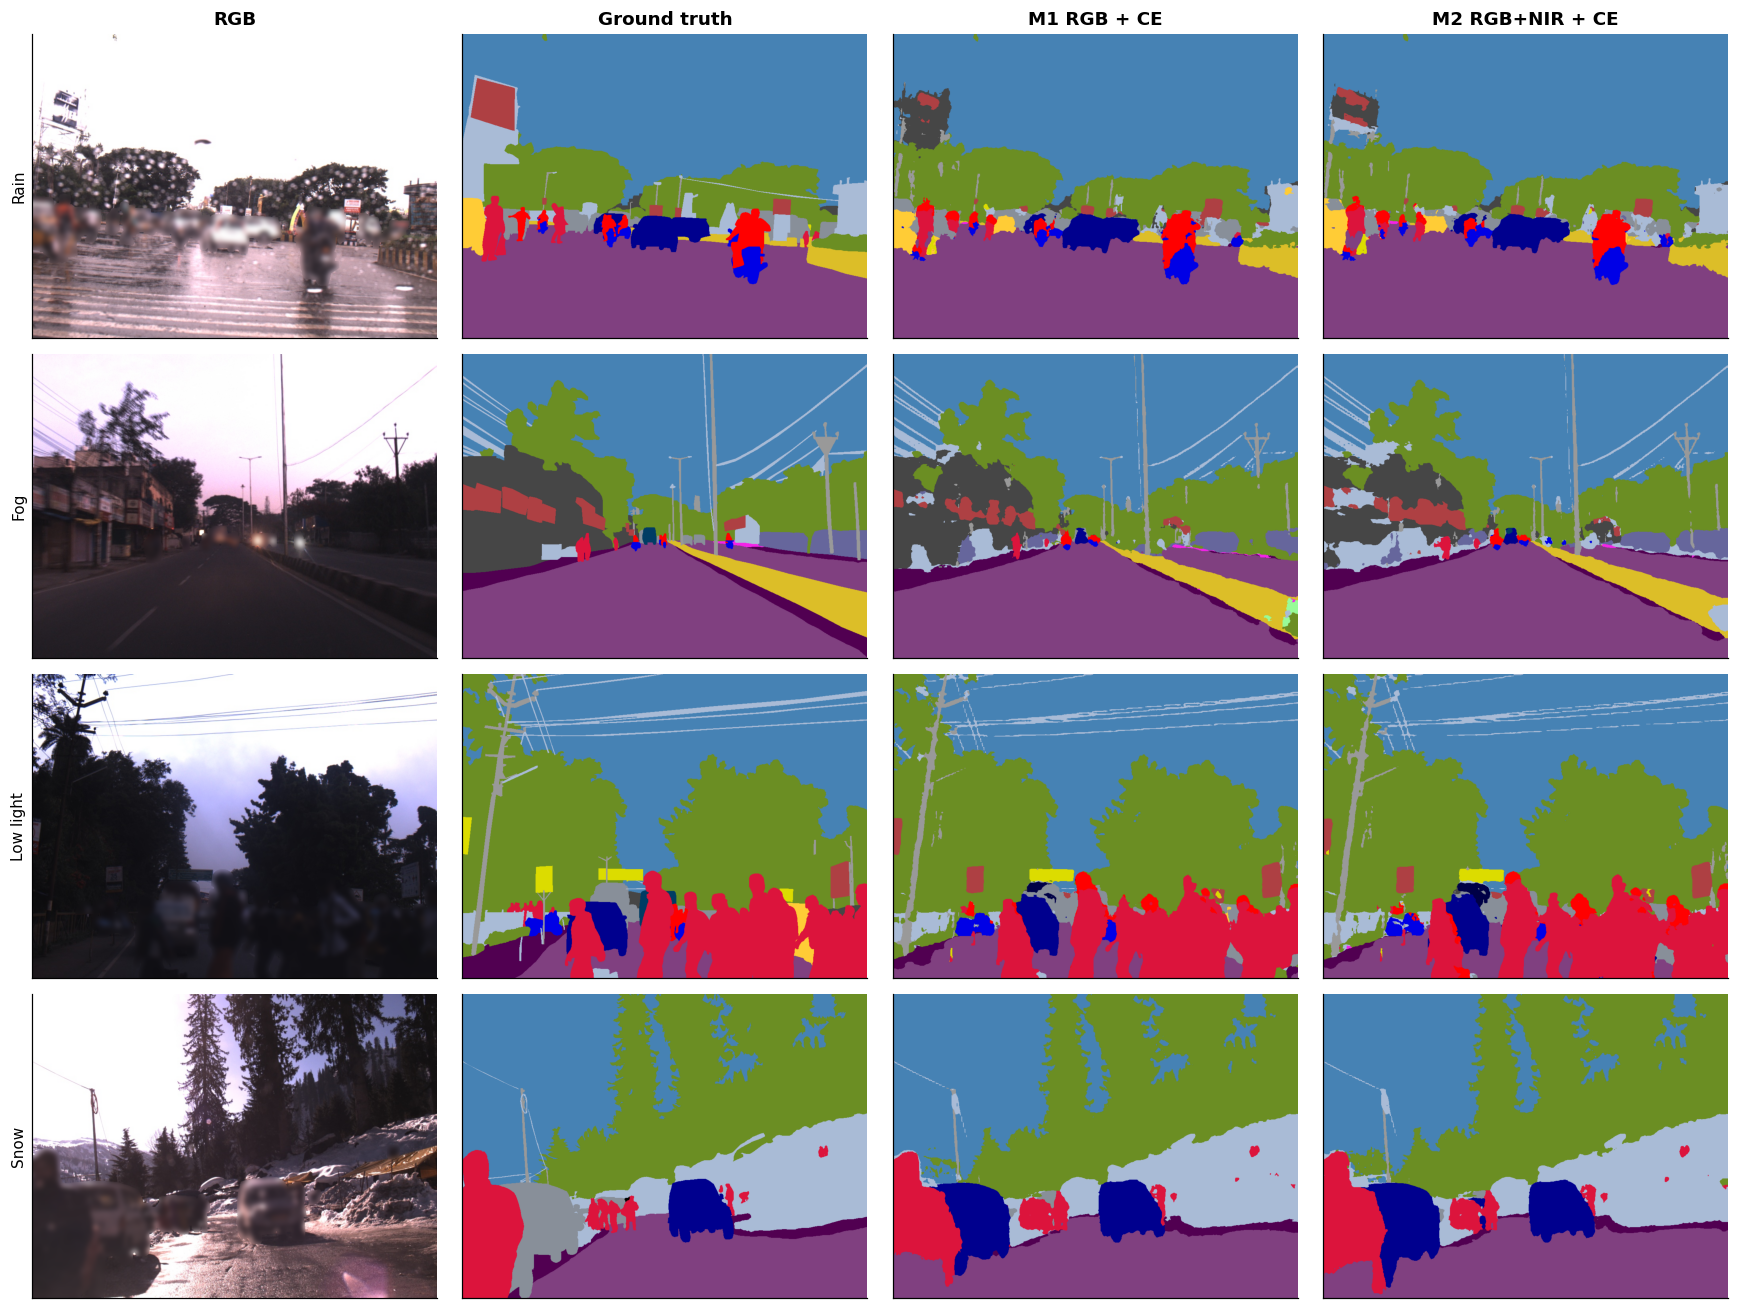

saved /content/drive/MyDrive/iddaw_outputs/figures/F_res_06_examples.png


In [23]:
# Qualitative examples (anonymised): RGB, ground truth, Model 1, best model
if "rgb_ce" in results:
    picks = []
    for c in COND_ORDER:
        sub = results["rgb_ce"][0]; sub = sub[(sub.condition == c) & (sub.has_vru == 1)].sort_values("vru_miss_pixels", ascending=False)
        if len(sub): picks.append(sub.iloc[0].image_id)
    rows_ = TEST.set_index("image_id").loc[picks].reset_index()
    cols_ = ["rgb_ce"] + ([best] if best != "rgb_ce" else [])
    preds = {}
    for m in cols_:
        model, mode = load_trained(m); preds[m] = list(predict_batch(model, rows_, mode)); del model
    fig, axs = plt.subplots(len(rows_), 2 + len(cols_), figsize=(4 * (2 + len(cols_)), 3 * len(rows_)), squeeze=False)
    for i, r in enumerate(rows_.itertuples()):
        gt = read_mask(r.mask_path); ims = [anonymise(read_rgb(r.rgb_path), gt), PALETTE[gt]] + [PALETTE[preds[m][i]] for m in cols_]
        for j, (im_, t) in enumerate(zip(ims, ["RGB", "Ground truth"] + [label[m] for m in cols_])):
            axs[i, j].imshow(im_); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
            if i == 0: axs[i, j].set_title(t)
        axs[i, 0].set_ylabel(COND_NAME[r.condition])
    fig.tight_layout(); savefig(fig, "F_res_06_examples")

**Observations**

- The examples with the most missed people pixels show that both models find large people and vehicles well.
- Errors are concentrated on small, distant or dark objects and on boundaries, matching the EDA finding on small people regions.

## 9. Preliminary statistical tests by research question
Single seed, so these are **preliminary**. Holm correction across the four conditions; bootstrap 95% CIs resample test images.

In [24]:
def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); adj = np.empty_like(p); run = 0
    for k, i in enumerate(o): run = max(run, (len(p) - k) * p[i]); adj[i] = min(1, run)
    return adj
def boot_ci(x, n=N_BOOT, seed=SEED):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 2: return (np.nan, np.nan)
    r = np.random.RandomState(seed); b = r.choice(x, (n, len(x)), replace=True).mean(1); return tuple(np.percentile(b, [2.5, 97.5]))
def paired(a, b, metric):
    m_ = a[["image_id", "condition", metric]].merge(b[["image_id", metric]], on="image_id", suffixes=("_a", "_b"))
    m_["d"] = m_[metric + "_b"] - m_[metric + "_a"]; return m_.dropna(subset=["d"])
tests = []
if "rgb_ce" in results:
    b = results["rgb_ce"][0].copy(); b["gap"] = b.miou_img - b.smiou_img
    groups_ = [b.loc[b.condition == c, "gap"].dropna() for c in COND_ORDER]
    H_, p_ = stats.kruskal(*groups_)
    tests.append({"RQ": "RQ1", "comparison": "gap (mIoU - SmIoU) across 4 conditions, Model 1", "test": "Kruskal-Wallis",
                  "statistic": H_, "p_value": p_, "effect": f"mean gap by condition: " + ", ".join(f"{COND_NAME[c]} {g.mean()*100:.2f}" for c, g in zip(COND_ORDER, groups_))})
    pw = []
    for i in range(4):
        for j in range(i + 1, 4):
            pw.append((f"{COND_NAME[COND_ORDER[i]]} vs {COND_NAME[COND_ORDER[j]]}", stats.mannwhitneyu(groups_[i], groups_[j]).pvalue))
    for (lab, p0), pa in zip(pw, holm([p for _, p in pw])):
        tests.append({"RQ": "RQ1", "comparison": "pairwise gap " + lab, "test": "Mann-Whitney U (Holm)", "statistic": np.nan, "p_value": pa, "effect": ""})
if "rgb_ce" in results and "rgbn_ce" in results:
    pm = paired(results["rgb_ce"][0], results["rgbn_ce"][0], "miou_img"); ps = []
    for c in COND_ORDER:
        d = pm.loc[pm.condition == c, "d"]
        ps.append(stats.wilcoxon(d).pvalue if (d != 0).sum() > 0 else 1.0)
    for c, pa in zip(COND_ORDER, holm(ps)):
        d = pm.loc[pm.condition == c, "d"]; lo, hi = boot_ci(d)
        tests.append({"RQ": "RQ2", "comparison": f"M2 - M1 per-image mIoU, {COND_NAME[c]}", "test": "Wilcoxon signed-rank (Holm)",
                      "statistic": np.nan, "p_value": pa, "effect": f"mean diff {d.mean()*100:.2f} pts [95% CI {lo*100:.2f}, {hi*100:.2f}]"})
if "rgb_ce" in results and "rgb_td" in results:
    sd = paired(results["rgb_ce"][0], results["rgb_td"][0], "smiou_img")["d"]; md = paired(results["rgb_ce"][0], results["rgb_td"][0], "miou_img")["d"]
    p_sup = stats.wilcoxon(sd, alternative="greater").pvalue if (sd != 0).sum() > 0 else 1.0
    lo, hi = boot_ci(sd)
    tests.append({"RQ": "RQ3", "comparison": "M3 - M1 per-image SmIoU (superiority)", "test": "Wilcoxon signed-rank, one-sided, alpha 0.025",
                  "statistic": np.nan, "p_value": p_sup, "effect": f"mean diff {sd.mean()*100:.2f} pts [95% CI {lo*100:.2f}, {hi*100:.2f}]"})
    lo, hi = boot_ci(md); t_lo = md.mean() - stats.t.ppf(0.975, len(md) - 1) * md.std(ddof=1) / np.sqrt(len(md))
    p_ni = stats.ttest_1samp(md + 0.01, 0, alternative="greater").pvalue
    tests.append({"RQ": "RQ3", "comparison": "M3 - M1 per-image mIoU (non-inferiority, margin 0.01)", "test": "One-sided t-test vs -0.01, alpha 0.025",
                  "statistic": np.nan, "p_value": p_ni, "effect": f"mean diff {md.mean()*100:.2f} pts; lower bound {t_lo*100:.2f} (pass if > -1.00)"})
if "rgb_ce" in results and len([m for m in MODELS if m in results]) > 1:
    best_other = max([m for m in MODELS if m in results and m != "rgb_ce"], key=lambda m: overall.loc[m, "SmIoU"])
    a = results["rgb_ce"][0]; c_ = results[best_other][0]
    mm = a[a.has_vru == 1][["image_id", "vru_miss_img"]].merge(c_[["image_id", "vru_miss_img"]], on="image_id", suffixes=("_base", "_best"))
    b_ = int(((mm.vru_miss_img_base == 1) & (mm.vru_miss_img_best == 0)).sum()); c2 = int(((mm.vru_miss_img_base == 0) & (mm.vru_miss_img_best == 1)).sum())
    p_mc = stats.binomtest(min(b_, c2), b_ + c2, 0.5).pvalue if b_ + c2 > 0 else 1.0
    tests.append({"RQ": "RQ4", "comparison": f"dangerous misses: M1 vs {label[best_other]} ({len(mm)} images with VRU)", "test": "McNemar exact",
                  "statistic": np.nan, "p_value": p_mc, "effect": f"miss rate {mm.vru_miss_img_base.mean()*100:.1f}% vs {mm.vru_miss_img_best.mean()*100:.1f}%; discordant b={b_}, c={c2}"})
tests = pd.DataFrame(tests)
if len(tests): savetab(tests.round(4), "T_statistical_tests")

,RQ,comparison,test,statistic,p_value,effect
0,RQ1,"gap (mIoU - SmIoU) across 4 conditions, Model 1",Kruskal-Wallis,22.659,0.000e+00,"mean gap by condition: Rain 9.11, Fog 7.70, Low light 8.84, Snow 10.11"
1,RQ1,pairwise gap Rain vs Fog,Mann-Whitney U (Holm),NaN,3.700e-03,
2,RQ1,pairwise gap Rain vs Low light,Mann-Whitney U (Holm),NaN,4.744e-01,
3,RQ1,pairwise gap Rain vs Snow,Mann-Whitney U (Holm),NaN,3.126e-01,
4,RQ1,pairwise gap Fog vs Low light,Mann-Whitney U (Holm),NaN,3.500e-02,
5,RQ1,pairwise gap Fog vs Snow,Mann-Whitney U (Holm),NaN,1.000e-04,
6,RQ1,pairwise gap Low light vs Snow,Mann-Whitney U (Holm),NaN,1.309e-01,
7,RQ2,"M2 - M1 per-image mIoU, Rain",Wilcoxon signed-rank (Holm),NaN,1.400e-03,"mean diff 0.51 pts [95% CI 0.26, 0.74]"
8,RQ2,"M2 - M1 per-image mIoU, Fog",Wilcoxon signed-rank (Holm),NaN,5.000e-03,"mean diff 0.28 pts [95% CI 0.02, 0.55]"
9,RQ2,"M2 - M1 per-image mIoU, Low light",Wilcoxon signed-rank (Holm),NaN,2.800e-03,"mean diff 0.58 pts [95% CI 0.21, 0.95]"


**Observations**

- **RQ1:** the gap between mIoU and SmIoU **differs by condition** (Kruskal–Wallis p < 0.001); it is largest in snow (10.1 points) and smallest in fog (7.7).
- **RQ2:** NIR fusion gives a **small but significant gain** in rain (+0.5), fog (+0.3) and low light (+0.6 points; Holm p < 0.01), but **not in snow** (p = 0.46), against the EDA expectation.
- **RQ3:** the tree loss at λ = 1 gave **no SmIoU gain** (−0.16 points, p = 0.94) but is **non-inferior on mIoU** (lower bound −0.21 > −1); λ must be tuned before a conclusion.
- **RQ4:** dangerous misses barely change with NIR (17.7% vs 17.3%, McNemar p = 0.76); all results are **preliminary (one seed)**.

## 10. Sample-size recheck with observed (pilot) standard deviations
Same formulas as the synopsis, with the planning standard deviations replaced by the values observed on the test set.

In [25]:
z = stats.norm.ppf
rows = []
if "rgb_ce" in results:
    b = results["rgb_ce"][0]; sg = (b.miou_img - b.smiou_img).groupby(b.condition).std().reindex(COND_ORDER).max()
    rows.append(["RQ1", "CI for mean gap per condition", "sigma", 0.15, sg, math.ceil(z(.975) ** 2 * sg ** 2 / 0.02 ** 2)])
if "rgbn_ce" in results:
    sdd = paired(results["rgb_ce"][0], results["rgbn_ce"][0], "miou_img").groupby("condition")["d"].std().max()
    rows.append(["RQ2", "Paired Wilcoxon, Holm (alpha 0.0125)", "sigma_d", 0.12, sdd, math.ceil((z(1 - .0125 / 2) + z(.8)) ** 2 * sdd ** 2 / 0.03 ** 2 / 0.955)])
if "rgb_td" in results:
    s1 = paired(results["rgb_ce"][0], results["rgb_td"][0], "smiou_img")["d"].std(); s2 = paired(results["rgb_ce"][0], results["rgb_td"][0], "miou_img")["d"].std()
    rows.append(["RQ3", "SmIoU superiority (one-sided 0.025)", "sigma_d", 0.10, s1, math.ceil((z(.975) + z(.8)) ** 2 * s1 ** 2 / 0.02 ** 2 / 0.955)])
    rows.append(["RQ3", "mIoU non-inferiority (margin 0.01)", "sigma_d", 0.06, s2, math.ceil((z(.975) + z(.8)) ** 2 * s2 ** 2 / 0.01 ** 2 / 0.955)])
ss = pd.DataFrame(rows, columns=["RQ", "method", "parameter", "planning value", "observed value", "required n (observed)"])
if len(ss): savetab(ss.round(4), "T_sample_size_recheck")
print("test images available per condition:", TE.condition.value_counts().reindex(COND_ORDER).to_dict(), "| total:", len(TE))

,RQ,method,parameter,planning value,observed value,required n (observed)
0,RQ1,CI for mean gap per condition,sigma,0.15,0.059,34
1,RQ2,"Paired Wilcoxon, Holm (alpha 0.0125)",sigma_d,0.12,0.030,12
2,RQ3,SmIoU superiority (one-sided 0.025),sigma_d,0.10,0.027,15
3,RQ3,mIoU non-inferiority (margin 0.01),sigma_d,0.06,0.020,32


test images available per condition: {'RAIN': 287, 'FOG': 292, 'LOWLIGHT': 217, 'SNOW': 217} | total: 1013


**Observations**

- Observed standard deviations are **much smaller than the planning values** (for example 0.059 vs 0.15 for RQ1).
- With the observed values, each RQ needs only **12–34 test images**, far fewer than the 1,013 available.
- The planning assumptions were conservative, so the test set has ample statistical power.

## 11. Exploratory: which image features predict a dangerous miss? (LightGBM + SHAP)
Target: whether Model 1 produced a dangerous miss on a test image that contains vulnerable road users. Features are image-level
statistics from Section 3. Validation: 5-fold cross-validation grouped by drive sequence (no sequence in both train and validation folds).
Compared with logistic regression as a simple alternative. Some features use the ground-truth mask, so this explains failures
rather than predicting them in deployment.

,model,CV ROC AUC (grouped 5-fold),n_images,miss_rate
0,LightGBM,0.818,751,0.177
1,Logistic regression,0.685,751,0.177


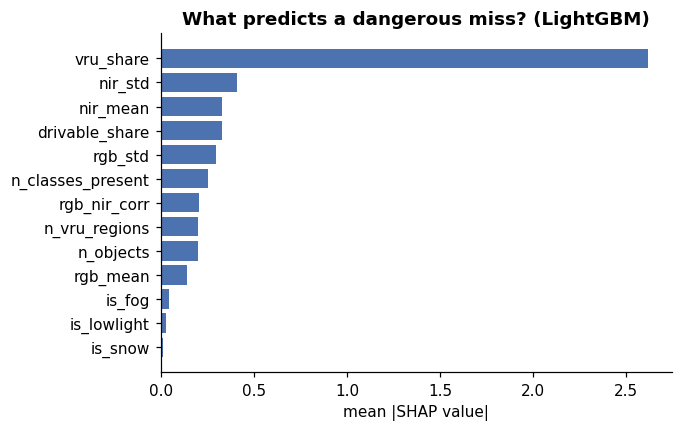

saved /content/drive/MyDrive/iddaw_outputs/figures/F_res_07_feature_importance.png


,feature,mean |SHAP value|
0,vru_share,2.614
1,nir_std,0.410
2,nir_mean,0.332
3,drivable_share,0.329
4,rgb_std,0.296
5,n_classes_present,0.254
6,rgb_nir_corr,0.205
7,n_vru_regions,0.201
8,n_objects,0.200
9,rgb_mean,0.140


In [26]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
FEATS = ["rgb_mean", "rgb_std", "nir_mean", "nir_std", "rgb_nir_corr", "n_objects", "n_classes_present", "n_vru_regions", "vru_share", "drivable_share",
         "is_fog", "is_lowlight", "is_snow"]
fi_rows = []
if "rgb_ce" in results:
    X = TE.copy()
    for c in ["FOG", "LOWLIGHT", "SNOW"]: X["is_" + c.lower()] = (X.condition == c).astype(int)
    X = X.merge(results["rgb_ce"][0][["image_id", "vru_miss_img"]], on="image_id")
    X = X[X.has_vru == 1].dropna(subset=FEATS)
    y_, g_ = X.vru_miss_img.values, X.split_group.values
    if len(X) >= 40 and 0 < y_.mean() < 1 and len(np.unique(g_)) >= 5:
        try:
            import lightgbm as lgb; gbm = lambda: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=10,
                                                                    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1); gname = "LightGBM"
        except ImportError:
            from sklearn.ensemble import HistGradientBoostingClassifier; gbm = lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, random_state=SEED); gname = "HistGradientBoosting"
        oof = {gname: np.zeros(len(X)), "Logistic regression": np.zeros(len(X))}
        for trn, val in GroupKFold(5).split(X, y_, g_):
            if len(np.unique(y_[trn])) < 2: continue
            m1 = gbm().fit(X.iloc[trn][FEATS], y_[trn]); oof[gname][val] = m1.predict_proba(X.iloc[val][FEATS])[:, 1]
            m2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X.iloc[trn][FEATS], y_[trn])
            oof["Logistic regression"][val] = m2.predict_proba(X.iloc[val][FEATS])[:, 1]
        auc = pd.DataFrame([{"model": k, "CV ROC AUC (grouped 5-fold)": roc_auc_score(y_, v), "n_images": len(X), "miss_rate": y_.mean()} for k, v in oof.items()])
        savetab(auc.round(3), "T_failure_model_auc")
        full = gbm().fit(X[FEATS], y_)
        try:
            import shap
            sv = shap.TreeExplainer(full).shap_values(X[FEATS]); sv = sv[1] if isinstance(sv, list) else sv
            imp = pd.Series(np.abs(sv).mean(0), index=FEATS); imp_name = "mean |SHAP value|"
        except Exception:
            from sklearn.inspection import permutation_importance
            imp = pd.Series(permutation_importance(full, X[FEATS], y_, n_repeats=20, random_state=SEED, scoring="roc_auc").importances_mean, index=FEATS)
            imp_name = "permutation importance (AUC drop)"
        imp = imp.sort_values()
        fig, ax = plt.subplots(figsize=(6, 4)); ax.barh(imp.index, imp.values, color="#4C72B0")
        ax.set_xlabel(imp_name); ax.set_title(f"What predicts a dangerous miss? ({gname})"); savefig(fig, "F_res_07_feature_importance")
        savetab(imp.sort_values(ascending=False).round(4).reset_index().rename(columns={"index": "feature", 0: imp_name}), "T_feature_importance")
    else:
        print("not enough test images with VRU / misses for this analysis yet:", len(X))

**Observations**

- LightGBM predicts which test images will contain a dangerous miss with **ROC AUC 0.82**, clearly better than logistic regression (0.69), using drive-grouped 5-fold cross-validation.
- The strongest factor is **how much of the image is people** (vru_share), followed by **NIR brightness and contrast** and the share of road.
- Once these image properties are known, the weather label itself adds little, so visibility conditions matter more than the weather name.
- This is exploratory: some features come from the ground truth, so it explains failures rather than predicting them in deployment.

## 12. Export results for the report
Creates `iddaw_outputs/results_for_report.zip` (figures, tables, logs; no images or model weights).
Download it and the executed notebook (File → Download → .ipynb).

In [27]:
summary = {"quick_test": QUICK_TEST, "pairs_after_cleaning": int(len(df)), "split": split_tab.to_dict(), "test_used": int(len(TEST)),
           "overall": overall.round(3).to_dict() if len(overall) else {}, "environment": env,
           "settings": {k: globals()[k] for k in ["SEED", "IMG_W", "IMG_H", "CROP", "BATCH", "STEPS", "LR", "WARMUP", "TD_LAMBDA", "MIN_MISS_AREA"]}}
json.dump(summary, open(os.path.join(OUT_DIR, "summary.json"), "w"), indent=2, default=str)
zf = os.path.join(OUT_DIR, "results_for_report.zip")
with zipfile.ZipFile(zf, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT_DIR):
        for f in files:
            p = os.path.join(root, f)
            if p.endswith((".pt", ".tmp", ".npy", ".zip")) or "/models/" in p and not f.endswith(".csv"): continue
            z.write(p, os.path.relpath(p, OUT_DIR))
print("saved", zf)

saved /content/drive/MyDrive/iddaw_outputs/results_for_report.zip


**Observations**

- All figures, tables and logs are exported to `iddaw_outputs/results_for_report.zip` for the report and the GitHub repository.
- No images or model weights are exported, in line with the dataset license.